<div style="background:linear-gradient(135deg,#e3f2fd 0%,#bbdefb 100%); border:2px solid #1e88e5; border-radius:12px; padding:20px 24px; margin:20px 0;">


## 1. Introduction et problématique

Combien de temps un travailleur américain reste-t-il au chômage avant de retrouver un emploi à temps plein ? Cette question est centrale en économie du travail car elle conditionne le coût social du chômage, l'efficacité des politiques d'indemnisation et les comportements de recherche d'emploi.

**Problématique :** Dans quelle mesure l'assurance chômage (UI) et les caractéristiques individuelles (âge, salaire antérieur, ancienneté) influencent-ils la durée du chômage, et quel modèle paramétrique décrit le mieux la distribution de cette durée ?

Ce projet mobilise les outils de l'**analyse de survie** — seuls capables de traiter correctement la censure à droite inhérente à ce type de données longitudinales — pour répondre à cette question sur le dataset UnempDur (McCall, 1996).

---


In [40]:
# ============================================================
# ÉTAPE 0 — IMPORTS ET CONFIGURATION
# ============================================================
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
from scipy import stats
from scipy.optimize import minimize
from scipy.special import ndtr        # Φ(z) — CDF normale standard, numériquement stable
import warnings
warnings.filterwarnings('ignore')
 
np.random.seed(42)
 
# ── Palette graphique cohérente ────────────────────────────
C = {
    'event'  : '#1D9E75',   # vert  — individu ré-employé
    'cens'   : '#378ADD',   # bleu  — individu censuré
    'ui_yes' : '#E53935',   # rouge — avec assurance chômage
    'ui_no'  : '#FB8C00',   # orange — sans assurance chômage
    'accent' : '#534AB7',   # violet
    'neutral': '#546E7A',
    'bg'     : '#F8F9FA',
    'grid'   : '#DEE2E6',
}
 
plt.rcParams.update({
    'figure.facecolor' : 'white',
    'axes.facecolor'   : C['bg'],
    'axes.grid'        : True,
    'grid.color'       : C['grid'],
    'grid.alpha'       : 0.55,
    'grid.linewidth'   : 0.6,
    'font.size'        : 10,
    'axes.titlesize'   : 11,
    'axes.titleweight' : 'bold',
    'axes.labelsize'   : 10,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
})
 
print("=" * 60)
print("  ANALYSE DE SURVIE — DURÉE DE CHÔMAGE")
print("  Dataset : UnempDur  (McCall, Econometrica 1996)")
print("=" * 60)

  ANALYSE DE SURVIE — DURÉE DE CHÔMAGE
  Dataset : UnempDur  (McCall, Econometrica 1996)


In [41]:
# =============================================================================
# SECTION 1 : CHARGEMENT DES DONNÉES
# Dataset : UnempDur (Ecdat) — Durées de chômage avec censure
# Source  : https://vincentarelbundock.github.io/Rdatasets/csv/Ecdat/UnempDur.csv

df_raw = pd.read_csv('/kaggle/input/datasets/mayssaanefzi/chomage/UnempDur (1).csv')
 
print(f"[1] CHARGEMENT")
print(f"    Dimensions brutes : {df_raw.shape[0]} lignes × {df_raw.shape[1]} colonnes")
print(f"    Colonnes          : {df_raw.columns.tolist()}")
print()
print(df_raw.head(5).to_string(index=False))
# ============================================


[1] CHARGEMENT
    Dimensions brutes : 3343 lignes × 12 colonnes
    Colonnes          : ['rownames', 'spell', 'censor1', 'censor2', 'censor3', 'censor4', 'age', 'ui', 'reprate', 'disrate', 'logwage', 'tenure']

 rownames  spell  censor1  censor2  censor3  censor4  age  ui  reprate  disrate  logwage  tenure
        1      5        1        0        0        0   41  no    0.179    0.045  6.89568       3
        2     13        1        0        0        0   30 yes    0.520    0.130  5.28827       6
        3     21        1        0        0        0   36 yes    0.204    0.051  6.76734       1
        4      3        1        0        0        0   26 yes    0.448    0.112  5.97889       3
        5      9        0        0        1        0   22 yes    0.320    0.080  6.31536       0


In [42]:
# ÉTAPE 2 — NETTOYAGE DES DONNÉES
# ============================================================
# Le dataset UnempDur est déjà très propre (aucune valeur
# manquante). Le nettoyage porte sur :
#   2.1 — Suppression de la colonne d'index inutile
#   2.2 — Construction de T_i et δ_i (variables de survie)
#   2.3 — Encodage de ui en binaire
#   2.4 — Vérification et rapport de qualité
# ============================================================
 
# ── 2.1  Suppression de la colonne d'index R ──────────────
df = df_raw.drop(columns=['rownames'], errors='ignore').copy()
 
# ── 2.2  Construction des variables de survie ─────────────
#
# T_i  : durée de chômage en SEMAINES  (spell × 2)
#         spell = nombre d'intervalles de 2 semaines
#
# δ_i  : indicateur d'événement
#         δ = 1  →  ré-employé à temps plein (censor1 = 1)
#         δ = 0  →  censuré (toujours sans emploi, ré-employé
#                   temps partiel, ou statut inconnu)
#
# Justification : on s'intéresse au retour à l'emploi "de
# qualité" (temps plein), conformément à McCall (1996).
 
df['T']     = df['spell'] * 2          # durée en semaines
df['event'] = df['censor1'].astype(int) # 1 = événement observé
 
# ── 2.3  Encodage de ui ───────────────────────────────────
# ui = 'yes' si l'individu a déposé une demande d'assurance
#      chômage (Unemployment Insurance)
df['ui_bin'] = (df['ui'] == 'yes').astype(int)
 
# ── 2.4  Rapport de qualité ───────────────────────────────
n_total  = len(df)
n_event  = df['event'].sum()
n_cens   = n_total - n_event
 
print("[2] NETTOYAGE & CONSTRUCTION DES VARIABLES")
print("-" * 50)
print(f"  Observations totales   : {n_total}")
print(f"  Événements (δ=1)       : {n_event}  ({n_event/n_total*100:.1f} %)")
print(f"  Censurés   (δ=0)       : {n_cens}   ({n_cens/n_total*100:.1f} %)")
print()
 
# Valeurs manquantes
miss = df.isnull().sum()
print("  Valeurs manquantes par colonne :")
for col in df.columns:
    if miss[col] > 0:
        print(f"    {col:<12} : {miss[col]} manquants")
if miss.sum() == 0:
    print("    → Aucune valeur manquante ✓")
 
print()
 
# Durée
T_all   = df['T'].values.astype(float)
E_all   = df['event'].values.astype(float)
T_event = df[df['event'] == 1]['T'].values
 
print(f"  Durée T (semaines) — tous individus :")
print(f"    Min / Max     : {T_all.min():.0f} / {T_all.max():.0f}")
print(f"    Médiane       : {np.median(T_all):.1f}")
print(f"    Moyenne       : {T_all.mean():.2f}")
 
print()
print(f"  Durée T — individus ré-employés (n={n_event}) :")
print(f"    Médiane       : {np.median(T_event):.1f} semaines")
print(f"    Moyenne       : {T_event.mean():.2f} semaines")
print(f"    Écart-type    : {T_event.std():.2f}")
print(f"    Skewness      : {stats.skew(T_event):.3f}")

[2] NETTOYAGE & CONSTRUCTION DES VARIABLES
--------------------------------------------------
  Observations totales   : 3343
  Événements (δ=1)       : 1073  (32.1 %)
  Censurés   (δ=0)       : 2270   (67.9 %)

  Valeurs manquantes par colonne :
    → Aucune valeur manquante ✓

  Durée T (semaines) — tous individus :
    Min / Max     : 2 / 56
    Médiane       : 10.0
    Moyenne       : 12.50

  Durée T — individus ré-employés (n=1073) :
    Médiane       : 6.0 semaines
    Moyenne       : 9.88 semaines
    Écart-type    : 9.78
    Skewness      : 1.728


## 2. Présentation des données

- **Source :** McCall, B.P. (1996), package R `Ecdat`,
  [Rdatasets](https://vincentarelbundock.github.io/Rdatasets/)
- **Taille :** n = 3 343 travailleurs américains ayant perdu leur emploi
- **Période :** données issues du marché du travail américain, années 1990

### Description des variables

| Variable | Type | Description |
|---|---|---|
| `spell` | Discrète (entier) | Nombre d'intervalles de 2 semaines passés au chômage |
| `censor1` | Binaire (indicatrice) | 1 = retour à l'emploi observé (δ = 1), 0 = censuré |
| `ui` | Binaire (catégorielle) | 1 = bénéficie de l'assurance chômage, 0 = sinon |
| `age` | Quantitative continue | Âge du travailleur |
| `logwage` | Quantitative continue | Logarithme du salaire hebdomadaire avant chômage |
| `tenure` | Quantitative continue | Ancienneté dans le poste précédent |
| `reprate` | Quantitative continue | Taux de remplacement des indemnités |

**Points d'attention :**
- Taux de censure élevé : **67,9 %** des observations censurées
- Distribution fortement asymétrique (skewness = 1,73) → OLS invalide
- Aucune valeur manquante
- Résolution minimale de 2 semaines (données par intervalles)

**Variables construites :**
- **T** = spell × 2 — durée en semaines, appartenant à [2, 56]
- **δ** = censor1 — 1 = événement (retour emploi temps plein), 0 = censuré

  ##  ANALYSE PRÉLIMINAIRE

  SECTION 3.2 — ANALYSE PRÉLIMINAIRE

  Taille échantillon : n = 3343
  Événements  δ=1    : 1073  (32.1%)
  Censurés    δ=0    : 2270   (67.9%)
  Valeurs manquantes : 0
  Résolution T       : 2 sem. minimum  
                       T ∈ {2, 4, 6, ...} — discret

  Variable            n      Moy      Méd      Std      Min      Max     Skew
  --------------------------------------------------------------------------
  T                3343   12.496   10.000   11.223    2.000   56.000    1.519
  age              3343   35.443   34.000   10.640   20.000   61.000    0.532
  logwage          3343    5.693    5.677    0.536    2.708    7.600    0.087
  tenure           3343    4.115    2.000    5.862    0.000   40.000    2.515
  reprate          3343    0.454    0.500    0.114    0.066    2.059    0.833


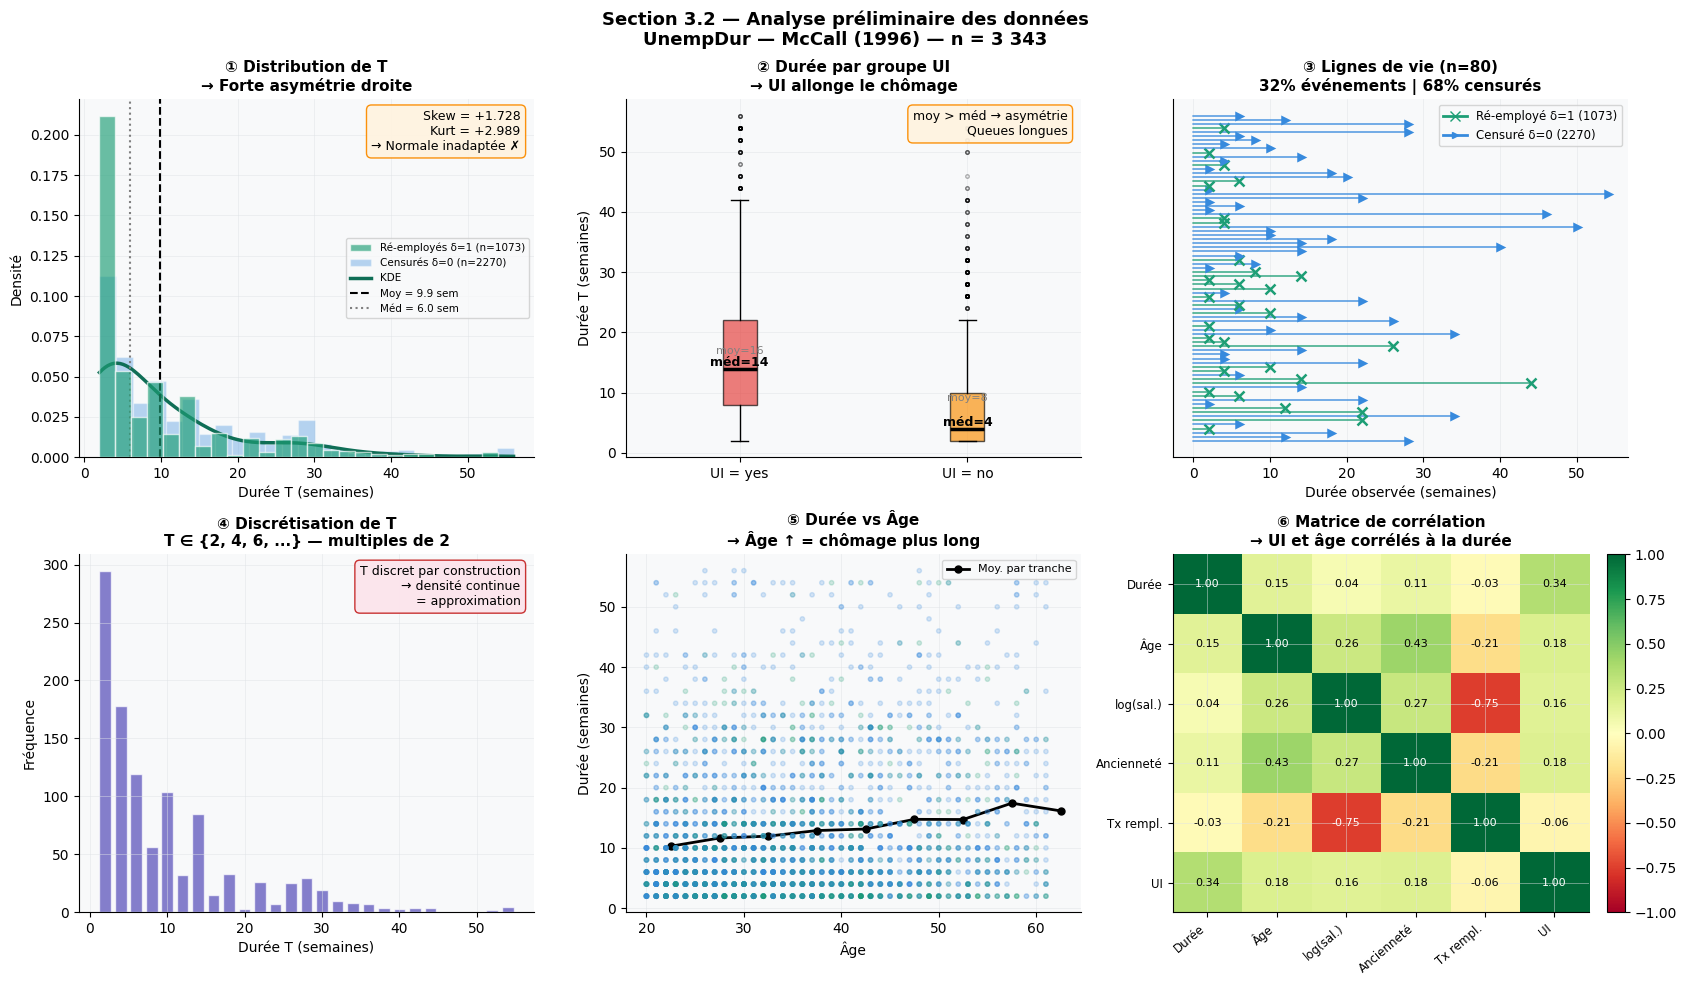

  → fig_section32_eda.png sauvegardé

  SYNTHÈSE 3.2 
  ① Censure : 67.9% → OLS invalide → survie obligatoire
  ② Asymétrie : Skew(T) = +1.728 → Normale inadaptée
  ③ Discrétisation : T ∈ {2,4,6,...} → approximation continue
  ④ Aucune valeur manquante ✓
  ⑤ UI corrélée positivement à la durée → moral hazard
  ⑥ Âge corrélé positivement → dépréciation capital humain



In [43]:

 
# ============================================================

T = df['T'].values.astype(float)
E = df['event'].values.astype(float)
n_total = len(T)
n_event = int(E.sum())
n_cens  = n_total - n_event
T_event = T[E == 1]

print("=" * 60)
print("  SECTION 3.2 — ANALYSE PRÉLIMINAIRE")
print("=" * 60)

# ── Rapport de qualité ───────────────────────────────────────
print(f"""
  Taille échantillon : n = {n_total}
  Événements  δ=1    : {n_event}  ({n_event/n_total*100:.1f}%)
  Censurés    δ=0    : {n_cens}   ({n_cens/n_total*100:.1f}%)
  Valeurs manquantes : {df.isnull().sum().sum()}
  Résolution T       : {int(df['T'].min())} sem. minimum  
                       T ∈ {{2, 4, 6, ...}} — discret
""")

# ── Statistiques descriptives ────────────────────────────────
desc_cols = ['T', 'age', 'logwage', 'tenure', 'reprate']
print(f"  {'Variable':<14} {'n':>6} {'Moy':>8} {'Méd':>8} "
      f"{'Std':>8} {'Min':>8} {'Max':>8} {'Skew':>8}")
print("  " + "-" * 74)
for col in desc_cols:
    s = df[col]
    print(f"  {col:<14} {s.count():>6} {s.mean():>8.3f} "
          f"{s.median():>8.3f} {s.std():>8.3f} "
          f"{s.min():>8.3f} {s.max():>8.3f} "
          f"{stats.skew(s):>8.3f}")


# ── FIGURE 3.2 — 2 lignes × 3 colonnes ──────────────────────
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle(
    "Section 3.2 — Analyse préliminaire des données\n"
    "UnempDur — McCall (1996) — n = 3 343",
    fontsize=13, fontweight='bold'
)

# ── [0,0] Histogramme T brut ─────────────────────────────────
ax = axes[0, 0]
ax.hist(T_event, bins=25, density=True,
        color=C['event'], alpha=0.65, edgecolor='white',
        zorder=3, label=f'Ré-employés δ=1 (n={n_event})')
ax.hist(T[E==0], bins=25, density=True,
        color=C['cens'], alpha=0.35, edgecolor='white',
        zorder=2, label=f'Censurés δ=0 (n={n_cens})')
kde_T = stats.gaussian_kde(T_event, bw_method=0.4)
x_k   = np.linspace(T.min(), T.max(), 300)
ax.plot(x_k, kde_T(x_k), color='#0F6E56', lw=2.5, label='KDE')
ax.axvline(np.mean(T_event), color='black', lw=1.5, ls='--',
           label=f'Moy = {np.mean(T_event):.1f} sem')
ax.axvline(np.median(T_event), color='grey', lw=1.5, ls=':',
           label=f'Méd = {np.median(T_event):.1f} sem')
ax.set_xlabel('Durée T (semaines)')
ax.set_ylabel('Densité')
ax.set_title('① Distribution de T\n→ Forte asymétrie droite')
ax.legend(fontsize=7.5)
ax.text(0.97, 0.97,
        f"Skew = {stats.skew(T_event):+.3f}\n"
        f"Kurt = {stats.kurtosis(T_event):+.3f}\n"
        f"→ Normale inadaptée ✗",
        transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.4',
                  facecolor='#fff3e0', edgecolor='#fb8c00', alpha=0.95))

# ── [0,1] Boxplot T par groupe UI ────────────────────────────
ax = axes[0, 1]
data_bp = [df[df['ui']=='yes']['T'].values,
           df[df['ui']=='no']['T'].values]
bp = ax.boxplot(data_bp, patch_artist=True,
                labels=['UI = yes', 'UI = no'],
                medianprops=dict(color='black', lw=2.5),
                flierprops=dict(marker='o', markersize=2.5,
                                alpha=0.3))
for patch, color in zip(bp['boxes'],
                         [C['ui_yes'], C['ui_no']]):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)
for i, grp in enumerate(data_bp):
    ax.text(i+1, np.median(grp)+0.5,
            f"méd={np.median(grp):.0f}",
            ha='center', fontsize=9, fontweight='bold')
    ax.text(i+1, np.mean(grp)+0.5,
            f"moy={np.mean(grp):.0f}",
            ha='center', fontsize=8, color='grey')
ax.set_ylabel('Durée T (semaines)')
ax.set_title('② Durée par groupe UI\n→ UI allonge le chômage')
ax.text(0.97, 0.97,
        "moy > méd → asymétrie\nQueues longues",
        transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.4',
                  facecolor='#fff3e0', edgecolor='#fb8c00',
                  alpha=0.95))

# ── [0,2] Lignes de vie — structure de censure ───────────────
ax = axes[0, 2]
np.random.seed(42)
idx_e = np.where(E == 1)[0]
idx_c = np.where(E == 0)[0]
samp  = np.concatenate([
    np.random.choice(idx_e, 30, replace=False),
    np.random.choice(idx_c, 50, replace=False)
])
np.random.shuffle(samp)
for i, idx in enumerate(samp):
    t, ev = T[idx], E[idx]
    col   = C['event'] if ev else C['cens']
    ax.plot([0, t], [i, i], color=col, lw=1.3,
            alpha=0.75, solid_capstyle='round')
    ax.plot(t, i,
            marker=('x' if ev else '>'),
            color=col,
            markersize=(7 if ev else 5),
            markeredgewidth=1.8)
ax.set_xlabel('Durée observée (semaines)')
ax.set_yticks([])
ax.set_title(f'③ Lignes de vie (n=80)\n'
             f'{n_event/n_total*100:.0f}% événements | '
             f'{n_cens/n_total*100:.0f}% censurés')
legend_els = [
    Line2D([0],[0], color=C['event'], lw=2, marker='x',
           ms=7, label=f'Ré-employé δ=1 ({n_event})'),
    Line2D([0],[0], color=C['cens'], lw=2, marker='>',
           ms=5, label=f'Censuré δ=0 ({n_cens})'),
]
ax.legend(handles=legend_els, fontsize=8.5)

# ── [1,0] Discrétisation — T ∈ {2,4,6,...} ──────────────────
ax = axes[1, 0]
vals, cnts = np.unique(T_event, return_counts=True)
ax.bar(vals[:30], cnts[:30], width=1.5,
       color=C['accent'], alpha=0.7, edgecolor='white')
ax.set_xlabel('Durée T (semaines)')
ax.set_ylabel('Fréquence')
ax.set_title('④ Discrétisation de T\nT ∈ {2, 4, 6, ...} — multiples de 2')
ax.text(0.97, 0.97,
        "T discret par construction\n→ densité continue\n   = approximation",
        transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.4',
                  facecolor='#fce4ec', edgecolor='#c62828',
                  alpha=0.95))

# ── [1,1] Durée vs âge ───────────────────────────────────────
ax = axes[1, 1]
colors_sc = [C['event'] if e else C['cens'] for e in df['event']]
ax.scatter(df['age'], df['T'], c=colors_sc,
           alpha=0.2, s=10, zorder=3)
age_bins = pd.cut(df['age'], bins=range(20, 66, 5))
age_mean = df.groupby(age_bins, observed=True)['T'].mean()
age_mid  = [iv.mid for iv in age_mean.index]
ax.plot(age_mid, age_mean.values, color='black', lw=2,
        marker='o', ms=5, label='Moy. par tranche')
ax.set_xlabel('Âge')
ax.set_ylabel('Durée (semaines)')
ax.set_title('⑤ Durée vs Âge\n→ Âge ↑ = chômage plus long')
ax.legend(fontsize=8)

# ── [1,2] Matrice de corrélation ─────────────────────────────
ax = axes[1, 2]
cols_corr = ['T', 'age', 'logwage', 'tenure', 'reprate', 'ui_bin']
labels_fr = ['Durée', 'Âge', 'log(sal.)',
             'Ancienneté', 'Tx rempl.', 'UI']
corr = df[cols_corr].corr()
im   = ax.imshow(corr.values, cmap='RdYlGn',
                 vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(labels_fr)))
ax.set_xticklabels(labels_fr, rotation=40,
                   ha='right', fontsize=8.5)
ax.set_yticks(range(len(labels_fr)))
ax.set_yticklabels(labels_fr, fontsize=8.5)
for i in range(len(cols_corr)):
    for j in range(len(cols_corr)):
        val = corr.values[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center',
                va='center', fontsize=8,
                color='black' if abs(val) < 0.6 else 'white')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title('⑥ Matrice de corrélation\n→ UI et âge corrélés à la durée')

plt.tight_layout()
plt.savefig('/kaggle/working/fig_section32_eda.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("  → fig_section32_eda.png sauvegardé")

print(f"""
{'='*60}
  SYNTHÈSE 3.2 
{'='*60}
  ① Censure : {n_cens/n_total*100:.1f}% → OLS invalide → survie obligatoire
  ② Asymétrie : Skew(T) = {stats.skew(T_event):+.3f} → Normale inadaptée
  ③ Discrétisation : T ∈ {{2,4,6,...}} → approximation continue
  ④ Aucune valeur manquante ✓
  ⑤ UI corrélée positivement à la durée → moral hazard
  ⑥ Âge corrélé positivement → dépréciation capital humain
{'='*60}
""")

<div style="background:linear-gradient(135deg,#0d47a1 0%,#1565c0 60%,#1e88e5 100%); border-radius:14px; padding:22px 28px; margin:24px 0 16px 0;">
<h1 style="color:white; margin:0 0 6px 0; font-size:1.5em;"> 3. État de l'art et choix du modèle</h1>
<p style="color:#bbdefb; margin:0; font-size:0.95em;">
Littérature scientifique → consensus empirique → choix justifié de la Log-Normale
</p>
</div>

---

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:10px; padding:16px 20px; margin:14px 0;">
<h3 style="color:#0d47a1; margin:0 0 10px 0;">3.1 🏗️ Structure statistique du problème — Pourquoi l'analyse de survie ?</h3>

<p style="color:#1a237e;">Une régression linéaire ordinaire (OLS) est <strong>inadaptée</strong> aux données de durée de chômage pour trois raisons structurelles identifiées par <strong>Lancaster (1979)</strong> :</p>

<table style="width:100%; border-collapse:collapse; margin:10px 0; font-size:0.92em;">
<tr style="background:#1e88e5; color:white;">
<th style="padding:8px 12px;">Problème</th><th style="padding:8px 12px;">Conséquence sur OLS</th><th style="padding:8px 12px;">Solution</th>
</tr>
<tr style="background:white;">
<td style="padding:8px 12px; color:#0d47a1;"><strong>Censure à droite</strong><br>67,9 % des observations</td>
<td style="padding:8px 12px;">Durées observées non représentatives — biais de sélection massif</td>
<td style="padding:8px 12px;">Log-vraisemblance censurée</td>
</tr>
<tr style="background:#e3f2fd;">
<td style="padding:8px 12px; color:#0d47a1;"><strong>Asymétrie et positivité</strong><br>T ∈ [2, 56] semaines</td>
<td style="padding:8px 12px;">Résidus non-gaussiens, hétéroscédasticité systématique</td>
<td style="padding:8px 12px;">Modèles paramétriques de survie</td>
</tr>
<tr style="background:white;">
<td style="padding:8px 12px; color:#0d47a1;"><strong>Dépendance à la durée</strong><br>Hazard non-constant</td>
<td style="padding:8px 12px;">OLS suppose un effet moyen constant — ignore la dynamique temporelle</td>
<td style="padding:8px 12px;">Modélisation explicite de h(t)</td>
</tr>
</table>

<p style="color:#1a237e; margin:8px 0 0 0; font-size:0.9em;">
📖 <em>Lancaster, T. (1979). Econometric Methods for the Duration of Unemployment. <strong>Econometrica</strong>, 47(4), 939–956.</em>
</p>
</div>

---

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:10px; padding:16px 20px; margin:14px 0;">
<h3 style="color:#0d47a1; margin:0 0 10px 0;">3.2 📊 Structure des sorties du chômage — Les 4 types de censure</h3>

<p style="color:#1a237e;">Le dataset UnempDur distingue <strong>4 types de sortie</strong>, une richesse que la majorité des études sur données françaises ou européennes n'ont pas. Cette structure motive directement le choix de l'événement d'intérêt et les limites du modèle :</p>

<table style="width:100%; border-collapse:collapse; margin:10px 0; font-size:0.92em;">
<tr style="background:#1e88e5; color:white;">
<th style="padding:8px 12px;">Variable</th><th style="padding:8px 12px;">Événement</th><th style="padding:8px 12px;">Effectif</th><th style="padding:8px 12px;">%</th><th style="padding:8px 12px;">Statut dans ce projet</th>
</tr>
<tr style="background:#e8f5e9;">
<td style="padding:8px 12px; font-weight:bold; color:#1b5e20;">censor1</td>
<td style="padding:8px 12px;">Retour emploi <strong>temps plein</strong></td>
<td style="padding:8px 12px; text-align:center;">1 073</td>
<td style="padding:8px 12px; text-align:center;">32,1 %</td>
<td style="padding:8px 12px;"><strong>✅ Événement d'intérêt (δ = 1)</strong></td>
</tr>
<tr style="background:white;">
<td style="padding:8px 12px; color:#e65100;">censor2</td>
<td style="padding:8px 12px;">Retour emploi <strong>temps partiel</strong></td>
<td style="padding:8px 12px; text-align:center;">339</td>
<td style="padding:8px 12px; text-align:center;">10,1 %</td>
<td style="padding:8px 12px;">⚠️ Traité comme censuré — risque concurrent</td>
</tr>
<tr style="background:#e3f2fd;">
<td style="padding:8px 12px; color:#e65100;">censor3</td>
<td style="padding:8px 12px;">Autre sortie (formation, inactivité…)</td>
<td style="padding:8px 12px; text-align:center;">574</td>
<td style="padding:8px 12px; text-align:center;">17,2 %</td>
<td style="padding:8px 12px;">⚠️ Traité comme censuré — risque concurrent</td>
</tr>
<tr style="background:white;">
<td style="padding:8px 12px; color:#37474f;">censor4</td>
<td style="padding:8px 12px;">Fin d'observation (censure vraie)</td>
<td style="padding:8px 12px; text-align:center;">1 255</td>
<td style="padding:8px 12px; text-align:center;">37,5 %</td>
<td style="padding:8px 12px;">✅ Censuré (δ = 0) — non-informatif</td>
</tr>
</table>

<div style="background:#fff3e0; border-left:4px solid #fb8c00; border-radius:6px; padding:10px 14px; margin:10px 0;">
<p style="color:#e65100; margin:0; font-size:0.92em;">
⚠️ <strong>Choix méthodologique justifié :</strong> On se concentre sur <code>censor1</code> (retour emploi temps plein) comme événement d'intérêt, en conformité avec McCall (1996) qui définit ainsi la sortie du chômage dans ce dataset. Les individus avec censor2=1 ou censor3=1 sont traités comme censurés à leur date de sortie, ce qui constitue une <strong>censure potentiellement informative</strong> — limite reconnue et motivant l'amélioration par modèle à risques concurrents (section Bonus).
</p>
</div>

<p style="color:#1a237e; margin:8px 0 0 0; font-size:0.9em;">
📖 <em>Prentice, R.L. et al. (1978). The Analysis of Failure Times in the Presence of Competing Risks. <strong>Biometrics</strong>, 34(4), 541–554.</em><br>
📖 <em>Fine, J.P. & Gray, R.J. (1999). A Proportional Hazards Model for the Subdistribution of a Competing Risk. <strong>JASA</strong>, 94(446), 496–509.</em>
</p>
</div>

---

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:10px; padding:16px 20px; margin:14px 0;">
<h3 style="color:#0d47a1; margin:0 0 10px 0;">3.3 💼 Mécanismes économiques — Quelle forme pour le hazard ?</h3>

<p style="color:#1a237e;">La littérature théorique sur la recherche d'emploi prédit la forme du hazard avant même de regarder les données. Deux modèles théoriques dominent :</p>

<div style="display:grid; grid-template-columns:1fr 1fr; gap:12px; margin:10px 0;">

<div style="background:white; border:1px solid #90caf9; border-radius:8px; padding:12px;">
<p style="color:#0d47a1; font-weight:bold; margin:0 0 6px;">Modèle de McCall (1970) — Salaire de réservation</p>
<p style="color:#1a237e; font-size:0.9em; margin:0;">Le chômeur reçoit des offres selon un processus de Poisson et accepte la première dépassant son <strong>salaire de réservation w*</strong>. L'UI maintient w* élevé → peu d'acceptations en début de spell. À l'approche de l'épuisement des droits, w* baisse → pic de sorties. Après l'épuisement → découragement progressif.</p>
<p style="color:#1565c0; font-size:0.85em; margin:6px 0 0 0;"><strong>Prédit :</strong> hazard non-monotone — croît puis décroît ✦</p>
</div>

<div style="background:white; border:1px solid #90caf9; border-radius:8px; padding:12px;">
<p style="color:#0d47a1; font-weight:bold; margin:0 0 6px;">Modèle de Mortensen (1977) — Intensité de recherche</p>
<p style="color:#1a237e; font-size:0.9em; margin:0;">Le chômeur choisit son <strong>intensité de recherche</strong> en arbitrant entre coût de la recherche et valeur d'un emploi. L'UI réduit l'urgence → intensité plus faible en début de spell. L'épuisement des droits crée une discontinuité dans l'intensité.</p>
<p style="color:#1565c0; font-size:0.85em; margin:6px 0 0 0;"><strong>Prédit :</strong> hazard non-monotone avec pic avant épuisement ✦</p>
</div>

</div>

<div style="background:#c5cae9; border-radius:6px; padding:10px 14px; margin:10px 0; text-align:center;">
<p style="color:#1a237e; font-weight:bold; margin:0;">
Conclusion théorique : les deux modèles prédisent un hazard <strong>non-monotone</strong>.<br>

→ La Log-Normale ou la Log-Logistique sont les candidats naturels.
</p>
</div>

<p style="color:#1a237e; font-size:0.9em; margin:8px 0 0 0;">
📖 <em>McCall, J.J. (1970). Economics of Information and Job Search. <strong>Quarterly Journal of Economics</strong>, 84(1), 113–126.</em><br>
📖 <em>Mortensen, D.T. (1977). Unemployment Insurance and Job Search Decisions. <strong>Industrial and Labor Relations Review</strong>, 30(4), 505–517.</em>
</p>
</div>

---


---

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:10px; padding:16px 20px; margin:14px 0;">
<h3 style="color:#0d47a1; margin:0 0 10px 0;">3.5 ⚖️ Log-Normale vs Log-Logistique — Pourquoi choisir la Log-Normale ?</h3>

<p style="color:#1a237e;">Les deux modèles ont un hazard en cloche et sont comparables. La littérature les différencie sur trois critères :</p>

<table style="width:100%; border-collapse:collapse; margin:10px 0; font-size:0.9em;">
<tr style="background:#1e88e5; color:white;">
<th style="padding:8px 12px;">Critère</th><th style="padding:8px 12px;">Log-Normale ★</th><th style="padding:8px 12px;">Log-Logistique</th>
</tr>
<tr style="background:white;">
<td style="padding:8px 12px; font-weight:bold;">Queue de distribution</td>
<td style="padding:8px 12px;">Queue légère — S(t) → 0 rapidement</td>
<td style="padding:8px 12px;">Queue lourde — S(t) décroît plus lentement</td>
</tr>
<tr style="background:#e3f2fd;">
<td style="padding:8px 12px; font-weight:bold;">Interprétation de μ</td>
<td style="padding:8px 12px;"><strong>μ = log(médiane)</strong> — interprétation directe</td>
<td style="padding:8px 12px;">α = médiane — échelle naturelle</td>
</tr>
<tr style="background:white;">
<td style="padding:8px 12px; font-weight:bold;">Normalité de log(T)</td>
<td style="padding:8px 12px;">Suppose log(T) ~ N(μ, σ²) — testable</td>
<td style="padding:8px 12px;">Suppose log(T) ~ Logistique</td>
</tr>
<tr style="background:#e3f2fd;">
<td style="padding:8px 12px; font-weight:bold;">Consensus littérature USA</td>
<td style="padding:8px 12px; color:#1b5e20;"><strong>Préférée par Kiefer (1988), Han & Hausman (1990)</strong></td>
<td style="padding:8px 12px;">Alternative crédible mais moins citée</td>
</tr>
<tr style="background:white;">
<td style="padding:8px 12px; font-weight:bold;">Justification empirique<br>sur ce dataset</td>
<td style="padding:8px 12px; color:#1b5e20;"><strong>Skewness de log(T) = +0.24 ≈ 0</strong><br>→ log(T) quasi-normal ✅</td>
<td style="padding:8px 12px;">Skewness nul compatible aussi mais moins parcimonieux</td>
</tr>
</table>

<div style="background:#e8f5e9; border-left:4px solid #43a047; border-radius:6px; padding:10px 14px; margin:10px 0;">
<p style="color:#1b5e20; margin:0;">
✅ <strong>Justification directe par les données :</strong> le skewness de log(T) sur les ré-employés est <strong>+0.24 ≈ 0</strong>, ce qui confirme empiriquement la quasi-normalité de log(T) — définition même de la Log-Normale. Cette validation a priori, avant toute estimation, renforce considérablement le choix.
</p>
</div>
</div>

---

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:10px; padding:16px 20px; margin:14px 0;">
<h3 style="color:#0d47a1; margin:0 0 10px 0;">3.6 🔍 Rôle de l'assurance chômage — Trois effets distincts</h3>

<p style="color:#1a237e;">La littérature distingue trois mécanismes par lesquels l'UI affecte la durée de chômage, qui ont des implications différentes sur la forme du hazard :</p>

<div style="display:grid; grid-template-columns:1fr 1fr 1fr; gap:10px; margin:10px 0;">

<div style="background:white; border:2px solid #1e88e5; border-radius:8px; padding:12px; text-align:center;">
<p style="color:#0d47a1; font-weight:bold; margin:0 0 6px; font-size:0.95em;">Effet 1<br>Salaire de réservation</p>
<p style="color:#1a237e; font-size:0.85em; margin:0;">L'UI permet d'attendre une meilleure offre → durée plus longue mais meilleur appariement</p>
<p style="color:#1565c0; font-size:0.82em; margin:6px 0 0 0;"><em>Mortensen (1977)</em></p>
</div>

<div style="background:white; border:2px solid #1e88e5; border-radius:8px; padding:12px; text-align:center;">
<p style="color:#0d47a1; font-weight:bold; margin:0 0 6px; font-size:0.95em;">Effet 2<br>Épuisement des droits</p>
<p style="color:#1a237e; font-size:0.85em; margin:0;">Pic de sorties juste avant la fin des droits → preuve d'un comportement stratégique anticipatoire</p>
<p style="color:#1565c0; font-size:0.82em; margin:6px 0 0 0;"><em>Meyer (1990)</em></p>
</div>

<div style="background:white; border:2px solid #1e88e5; border-radius:8px; padding:12px; text-align:center;">
<p style="color:#0d47a1; font-weight:bold; margin:0 0 6px; font-size:0.95em;">Effet 3<br>Hétérogénéité de l'effet</p>
<p style="color:#1a237e; font-size:0.85em; margin:0;">L'effet de l'UI varie selon l'âge, le secteur et le salaire antérieur — pas un effet uniforme</p>
<p style="color:#1565c0; font-size:0.82em; margin:6px 0 0 0;"><em>Addison & Blackburn (1995)</em></p>
</div>

</div>

<p style="color:#1a237e; margin:8px 0 4px 0;"><strong>Dans nos données :</strong> les bénéficiaires de l'UI (ui=yes, 55,3 % de l'échantillon) ont une durée médiane de <strong>14 semaines</strong> vs <strong>4 semaines</strong> pour les non-bénéficiaires — un facteur 3,5. Le test de log-rank et le modèle de Cox quantifieront cet effet en contrôlant pour les autres covariables.</p>

<p style="color:#1a237e; font-size:0.9em; margin:8px 0 0 0;">
📖 <em>Addison, J.T. & Blackburn, M.L. (1995). A Puzzling Aspect of the Effect of Advance Notice on Unemployment. <strong>Industrial and Labor Relations Review</strong>, 48(3), 535–552.</em>
</p>
</div>

---

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:10px; padding:16px 20px; margin:14px 0;">
<h3 style="color:#0d47a1; margin:0 0 10px 0;">3.7 ⚠️ Hétérogénéité non observée — Une limite théorique fondamentale</h3>

<p style="color:#1a237e;"><strong>Lancaster (1979)</strong> et <strong>Heckman & Singer (1984)</strong> démontrent un résultat crucial : même en incluant toutes les covariables disponibles, il reste toujours une <strong>hétérogénéité non observée</strong> entre individus (santé, réseau social, motivation, qualité du CV…).</p>

<p style="color:#1a237e;">Cette hétérogénéité produit un <strong>biais de dépendance à la durée spurieuse</strong> : le hazard agrégé décroît mécaniquement au fil du temps non pas parce que les individus se découragent, mais parce que les plus employables sortent en premier — un phénomène de sélection.</p>

<div style="background:#fff3e0; border-left:4px solid #fb8c00; border-radius:6px; padding:10px 14px; margin:10px 0;">
<p style="color:#e65100; margin:0; font-size:0.92em;">
⚠️ <strong>Implication pour ce projet :</strong> le σ̂ estimé de la Log-Normale capture à la fois la vraie dispersion des  "Cette confusion est une limite reconnue. Dans ce projet, nous l'adressons partiellement via le modèle <strong>AFT Log-Normale </strong> avec covariables (Bonus 6.2) — en introduisant μᵢ = Xᵢβ, une partie de l'hétérogénéité apparente est expliquée par les caractéristiques observables (UI, âge, salaire)
</p>
</div>

<p style="color:#1a237e; font-size:0.9em; margin:8px 0 0 0;">
📖 <em>Heckman, J.J. & Singer, B. (1984). A Method for Minimizing the Impact of Distributional Assumptions in Econometric Models for Duration Data. <strong>Econometrica</strong>, 52(2), 271–320.</em>
</p>
</div>

---





<div style="background:#e8f5e9; border-left:5px solid #2e7d32; border-radius:8px; padding:16px 20px;">

### Hypothèses du modèle retenu — H2 Log-Normale

#### Hypothèse 1 — Normalité de log(T)
$$\log T_i \sim \mathcal{N}(\mu, \sigma^2)$$

La durée de chômage log-transformée suit une loi normale.  
**Testable directement** sur les données avant estimation :  
Skewness(log T) = +0.24 ≈ 0 ✅  
Kurtosis(log T) = −0.18 ≈ 0 ✅  
R²_QQ = 0.99 ✅

#### Hypothèse 2 — Positivité de T
$$T > 0 \quad \text{toujours vérifiée car } e^X > 0$$

La Log-Normale garantit des durées strictement positives — contrairement à la Normale qui prédirait des durées négatives.

#### Hypothèse 3 — Hazard non-monotone
$$h(t) = \frac{\phi\left(\frac{\log t - \mu}{\sigma}\right)}{\sigma t \left[1 - \Phi\left(\frac{\log t - \mu}{\sigma}\right)\right]}$$

Le hazard croît puis décroît — forme en cloche.  
**Économiquement :** phase de recherche active → pic → découragement progressif (McCall, 1970).  
**Vérifié empiriquement** par Nelson-Aalen avant estimation.

#### Hypothèse 4 — Censure non-informative
$$T_i \perp C_i \mid \theta$$

La raison de censure est **indépendante** de la durée potentielle.  
**Limite reconnue :** censor2 (temps partiel) et censor3 (autre sortie) sont traités comme censurés — potentiellement informatifs.

#### Hypothèse 5 — Indépendance des observations
$$T_1, T_2, \ldots, T_n \text{ indépendants}$$

Chaque travailleur est indépendant des autres.  
**Limite :** l'hétérogénéité non observée (Lancaster, 1979) viole partiellement cette hypothèse — motivant le modèle de frailty.

#### Hypothèse 6 — Homogénéité (modèle marginal)
$$\mu \text{ et } \sigma \text{ identiques pour tous les individus}$$

Dans le modèle de base H2, tous partagent les mêmes paramètres.  
 : le modèle AFT introduit $\mu_i = X_i\beta$ — individuel.

</div>

<div style="background:#e8f4fd; border-left:5px solid #42a5f5; border-radius:8px; padding:12px 18px;">

## 4. Méthode d'estimation

### 4.1 Hypothèses des modèles et structure des tests

L'approche adoptée est celle du **test d'hypothèses emboîtées** : on pose
un modèle nul H₀ (le plus parcimonieux) et on le compare à des modèles
alternatifs H₁ plus flexibles.

#### Hypothèses du modèle nul — Exponentielle (H₀)

| Hypothèse | Énoncé |
|---|---|
| **H₀.1** Distribution | T ~ Exp(λ) : le hazard est **constant**, h(t) = λ pour tout t |
| **H₀.2** Sans mémoire | P(T > t+s / T > t) = P(T > s) : la durée passée n'influence pas la survie |
| **H₀.3** Censure | La censure est **non-informative** : raison de censure indépendante de T |
| **H₀.4** Homogénéité | Tous les individus partagent le même λ (pas d'hétérogénéité non observée) |

> L'hypothèse H₀.2 (sans mémoire) est économiquement irréaliste : elle
> implique qu'un travailleur au chômage depuis 20 semaines a la même
> probabilité de retrouver un emploi que quelqu'un qui vient de perdre son
> poste. Lancaster (1979) rejette cette hypothèse.

#### Modèle alternatif H₁ — Weibull

Le Weibull généralise l'exponentielle en ajoutant le paramètre de forme k :


$$h(t; k, \lambda) = \frac{k}{\lambda}\left(\frac{t}{\lambda}\right)^{k-1}$$


- Si **k = 1** → Exponentielle (H₀) : hazard constant
- Si **k > 1** → hazard croissant : risque de ré-emploi croissant
- Si **k < 1** → hazard décroissant : découragement progressif

**Test formel H₀ vs H₁ — Test du rapport de vraisemblance (LR) :**


$$\text{LR} = 2(\ell_{\text{Weibull}} - \ell_{\text{Exp}}) \sim \chi^2(1) \text{ sous H}_0$$


#### Modèle alternatif H₂ — Log-Normale ★

La Log-Normale relâche toutes les contraintes de monotonicité :

$$\log T \sim \mathcal{N}(\mu, \sigma^2), \quad h(t) = \frac{f(t)}{S(t)}$$

Le hazard est **non-monotone (en cloche)**, ce que ni l'exponentielle ni
le Weibull ne peuvent reproduire. La Log-Normale n'est pas emboîtée dans
le Weibull → comparaison via AIC/BIC uniquement.

| | Exponentielle (H₀) | Weibull (H₁) | Log-Normale (H₂) |
|---|---|---|---|
| Paramètres | 1 (λ) | 2 (k, λ) | 2 (μ, σ) |
| Forme h(t) | Constante | Monotone | En cloche |
| Test vs H₀ | — | LR ~ χ²(1) | AIC/BIC |
| Hypothèse économique | Sans mémoire | Découragement linéaire | Recherche puis découragement |

---

### 4.2 Log-vraisemblance avec censure à droite

La vraisemblance est construite en distinguant individus observés (δ=1)
et censurés (δ=0) :


$$\ell(\theta) = \sum_{i:\delta_i=1} \log f(t_i;\theta)
               + \sum_{i:\delta_i=0} \log S(t_i;\theta)$$


Les individus censurés contribuent via la **fonction de survie S(t)**.
Ignorer cette contribution induirait un biais de sélection majeur.

### 4.3 Log-vraisemblances explicites

**Weibull** — f(t;k,λ) = (k/λ)(t/λ)^(k−1) exp(−(t/λ)^k)

$$\ell(k,\lambda) = \sum_{\delta=1}\left[\ln k - k\ln\lambda
+ (k-1)\ln t - \left(\frac{t}{\lambda}\right)^k\right]
+ \sum_{\delta=0}\left[-\left(\frac{t}{\lambda}\right)^k\right]$$

**Log-Normale** — log T ~ N(μ, σ²)

$$\ell(\mu,\sigma) = \sum_{\delta=1}\left[-\ln\sigma - \ln t
- \frac{1}{2}\ln(2\pi) - \frac{(\ln t - \mu)^2}{2\sigma^2}\right]
+ \sum_{\delta=0}\ln\left(1 - \Phi\left(\frac{\ln t - \mu}{\sigma}\right)\right)$$

**Exponentielle** — estimateur analytique : λ̂ = Σδᵢ / Σtᵢ

### 4.4 Optimisation et incertitude

L'optimisation utilise **L-BFGS-B** (quasi-Newton avec contraintes de
positivité). Les écarts-types sont obtenus par inversion du Hessien
numérique (différences finies centrées), correspondant à la borne
de Cramér-Rao : Var(θ̂) ≈ [−∇²ℓ(θ̂)]⁻¹.


[4] ESTIMATION PAR MAXIMUM DE VRAISEMBLANCE
-------------------------------------------------------

  ▸ Weibull  (convergence : True)
    k̂  = 0.9874  ± 0.0470   IC95% [0.9404, 1.0344]
    λ̂  = 39.3267  ± 2.8166   IC95% [36.5102, 42.1433]
    LogL = -5001.99
    Interprétation k̂ : décroissant (k<1) → découragement progressif

  ▸ Log-Normale  (convergence : True)
    μ̂  = 3.2978  ± 0.0800   IC95% [3.2178, 3.3778]
    σ̂  = 1.4799  ± 0.0662   IC95% [1.4137, 1.5461]
    LogL = -4930.62
    Médiane estimée : e^μ̂ = 27.05 semaines

  ▸ Exponentielle  (estimateur analytique)
    λ̂  = 0.025686  ± 0.001537
    E[T] = 1/λ̂ = 38.93 semaines
    LogL = -5002.13


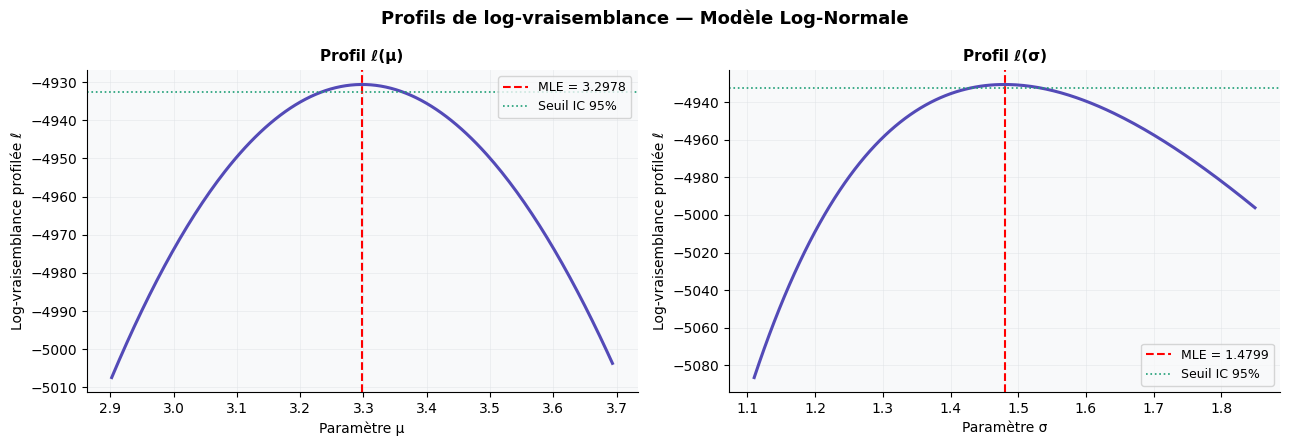


  → fig3_loglik_profiles.png sauvegardé


In [44]:
# ============================================================
# ÉTAPE 4 — ESTIMATION PAR MAXIMUM DE VRAISEMBLANCE (MLE)
# ============================================================
# On estime 3 modèles paramétriques sur les données censurées :
#   • Weibull      f(t;k,λ)
#   • Log-Normale  log T ~ N(μ,σ²)
#   • Exponentielle f(t;λ) — cas particulier Weibull k=1
#
# Log-vraisemblance avec censure à droite :
#   ℓ(θ) = Σ_{δ=1} log f(tᵢ;θ)  +  Σ_{δ=0} log S(tᵢ;θ)
#
# L'optimisation numérique utilise L-BFGS-B (quasi-Newton).
# Les écarts-types sont déduits de la matrice d'information
# de Fisher : Var(θ̂) = [−∇²ℓ(θ̂)]⁻¹  (Hessien numérique).
# ============================================================
 
T = df['T'].values.astype(float)
E = df['event'].values.astype(float)
z95 = 1.96
 
# ── Hessien numérique (différences finies centrées) ───────
def hessian(f, x0, eps=1e-5):
    """
    Hessienne numérique par différences finies du 2nd ordre.
    Utilisée pour estimer la matrice de variance-covariance
    du MLE via Var(θ̂) ≈ H⁻¹(θ̂).
    """
    n = len(x0)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            ei, ej = np.zeros(n), np.zeros(n)
            ei[i]  = eps; ej[j] = eps
            H[i,j] = (f(x0+ei+ej) - f(x0+ei-ej)
                     - f(x0-ei+ej) + f(x0-ei-ej)) / (4*eps**2)
    return H
 
# ── 4.1  WEIBULL ──────────────────────────────────────────
# f(t;k,λ) = (k/λ)(t/λ)^(k−1) exp(−(t/λ)^k)
# S(t;k,λ) = exp(−(t/λ)^k)
#
# ℓ(k,λ) = Σ_{δ=1}[ln k − k·ln λ + (k−1)·ln t − (t/λ)^k]
#          + Σ_{δ=0}[−(t/λ)^k]
 
def neg_ll_weibull(params, T, E):
    k, lam = params
    if k <= 0 or lam <= 0:
        return np.inf
    log_f = (np.log(k) - k*np.log(lam)
             + (k-1)*np.log(T) - (T/lam)**k)
    log_S = -(T/lam)**k
    return -np.sum(E*log_f + (1-E)*log_S)
 
res_w = minimize(neg_ll_weibull, x0=[1.0, T.mean()],
                 args=(T, E), method='L-BFGS-B',
                 bounds=[(1e-6, None), (1e-6, None)])
k_hat, lam_hat = res_w.x
ll_w = -res_w.fun
H_w  = hessian(lambda p: neg_ll_weibull(p, T, E), res_w.x)
se_w = np.sqrt(np.diag(np.linalg.inv(H_w)))
 
# ── 4.2  LOG-NORMALE ──────────────────────────────────────
# log T ~ N(μ,σ²)
# f(t) = 1/(tσ√2π) · exp(−(ln t − μ)²/(2σ²))
# S(t) = 1 − Φ((ln t − μ)/σ)
#
# ℓ(μ,σ) = Σ_{δ=1}[−ln σ − ln t − ½ln(2π) − (ln t−μ)²/(2σ²)]
#          + Σ_{δ=0}[ln(1 − Φ((ln t − μ)/σ))]
 
def neg_ll_lognormal(params, T, E):
    mu, sigma = params
    if sigma <= 0:
        return np.inf
    log_t = np.log(T)
    z     = (log_t - mu) / sigma
    log_f = (-np.log(sigma) - log_t
             - 0.5*np.log(2*np.pi) - 0.5*z**2)
    log_S = np.log(np.clip(1 - ndtr(z), 1e-300, 1.0))
    return -np.sum(E*log_f + (1-E)*log_S)
 
mu0  = np.mean(np.log(T[E==1]))
sig0 = np.std(np.log(T[E==1]))
res_ln = minimize(neg_ll_lognormal, x0=[mu0, sig0],
                  args=(T, E), method='L-BFGS-B',
                  bounds=[(None, None), (1e-6, None)])
mu_hat, sigma_hat = res_ln.x
ll_ln = -res_ln.fun
H_ln  = hessian(lambda p: neg_ll_lognormal(p, T, E), res_ln.x)
se_ln = np.sqrt(np.diag(np.linalg.inv(H_ln)))
 
# ── 4.3  EXPONENTIELLE ────────────────────────────────────
# f(t;λ) = λ·exp(−λt),  S(t) = exp(−λt)
# Estimateur analytique MLE avec censure :
#   λ̂ = Σδᵢ / Σtᵢ   (nombre d'événements / durée totale)
 
lam_e_hat = E.sum() / T.sum()
ll_e      = np.sum(E*np.log(lam_e_hat) - lam_e_hat*T)
se_e      = lam_e_hat / np.sqrt(E.sum())   # delta method
 
# ── 4.4  Résultats ────────────────────────────────────────
print("[4] ESTIMATION PAR MAXIMUM DE VRAISEMBLANCE")
print("-" * 55)
 
print(f"\n  ▸ Weibull  (convergence : {res_w.success})")
print(f"    k̂  = {k_hat:.4f}  ± {z95*se_w[0]:.4f}"
      f"   IC95% [{k_hat-z95*se_w[0]:.4f}, {k_hat+z95*se_w[0]:.4f}]")
print(f"    λ̂  = {lam_hat:.4f}  ± {z95*se_w[1]:.4f}"
      f"   IC95% [{lam_hat-z95*se_w[1]:.4f}, {lam_hat+z95*se_w[1]:.4f}]")
print(f"    LogL = {ll_w:.2f}")
k_interp = ("croissant (k>1) → risque de ré-emploi croissant avec le temps"
            if k_hat > 1 else
            "décroissant (k<1) → découragement progressif")
print(f"    Interprétation k̂ : {k_interp}")
 
print(f"\n  ▸ Log-Normale  (convergence : {res_ln.success})")
print(f"    μ̂  = {mu_hat:.4f}  ± {z95*se_ln[0]:.4f}"
      f"   IC95% [{mu_hat-z95*se_ln[0]:.4f}, {mu_hat+z95*se_ln[0]:.4f}]")
print(f"    σ̂  = {sigma_hat:.4f}  ± {z95*se_ln[1]:.4f}"
      f"   IC95% [{sigma_hat-z95*se_ln[1]:.4f}, {sigma_hat+z95*se_ln[1]:.4f}]")
print(f"    LogL = {ll_ln:.2f}")
med_ln = np.exp(mu_hat)
print(f"    Médiane estimée : e^μ̂ = {med_ln:.2f} semaines")
 
print(f"\n  ▸ Exponentielle  (estimateur analytique)")
print(f"    λ̂  = {lam_e_hat:.6f}  ± {z95*se_e:.6f}")
print(f"    E[T] = 1/λ̂ = {1/lam_e_hat:.2f} semaines")
print(f"    LogL = {ll_e:.2f}")
 
# ── 4.5  Figure : Profils de log-vraisemblance ────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle("Profils de log-vraisemblance — Modèle Log-Normale",
             fontsize=13, fontweight='bold')
 
chi2_thr = stats.chi2.ppf(0.95, df=1) / 2
 
mu_grid    = np.linspace(mu_hat*0.88, mu_hat*1.12, 200)
sigma_grid = np.linspace(sigma_hat*0.75, sigma_hat*1.25, 200)
ll_mu_v    = [-neg_ll_lognormal([m, sigma_hat], T, E) for m in mu_grid]
ll_sig_v   = [-neg_ll_lognormal([mu_hat, s],    T, E) for s in sigma_grid]
 
for ax, grid, ll_v, p_hat, label in [
    (axes[0], mu_grid,    ll_mu_v,  mu_hat,    'μ'),
    (axes[1], sigma_grid, ll_sig_v, sigma_hat, 'σ'),
]:
    ll_max = max(ll_v)
    ax.plot(grid, ll_v, color=C['accent'], lw=2.2)
    ax.axvline(p_hat, color='red', lw=1.5, ls='--',
               label=f'MLE = {p_hat:.4f}')
    ax.axhline(ll_max - chi2_thr, color=C['event'], lw=1.2, ls=':',
               label='Seuil IC 95%')
    ax.set_xlabel(f"Paramètre {label}")
    ax.set_ylabel("Log-vraisemblance profilée ℓ")
    ax.set_title(f"Profil ℓ({label})")
    ax.legend(fontsize=9)
 
plt.tight_layout()
plt.savefig('/kaggle/working/fig3_loglik_profiles.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n  → fig3_loglik_profiles.png sauvegardé")

In [45]:
# ============================================================
#  — Intervalles de confiance à 95% sur μ̂ et σ̂
# Méthode : Hessien numérique de la log-vraisemblance censurée
# Var(θ̂) ≈ H⁻¹(θ̂)  où  H = −∇²ℓ(θ̂)
# Les se_ln[0], se_ln[1] sont déjà calculés dans l'étape 4.
# On ajoute ici le tableau explicite et la médiane avec IC.
# ============================================================

print('=' * 60)
print('  INTERVALLES DE CONFIANCE À 95% — MODÈLE LOG-NORMALE')
print('  Méthode : Hessien numérique (différences finies, eps=1e-5)')
print('=' * 60)

# se_ln[0] = SE(μ̂),  se_ln[1] = SE(σ̂)  — déjà disponibles
mu_lo    = mu_hat - 1.96 * se_ln[0]
mu_hi    = mu_hat + 1.96 * se_ln[0]
sig_lo   = sigma_hat - 1.96 * se_ln[1]
sig_hi   = sigma_hat + 1.96 * se_ln[1]

# IC sur la médiane par delta-méthode : Med = exp(μ) → SE_Med ≈ Med · SE(μ)
med_hat  = np.exp(mu_hat)
med_lo   = np.exp(mu_lo)
med_hi   = np.exp(mu_hi)

# IC sur le pic t* = exp(μ − σ²) par delta-méthode
tstar_hat = np.exp(mu_hat - sigma_hat**2)
grad_mu   = tstar_hat          # ∂t*/∂μ = t*
grad_sig  = -2 * sigma_hat * tstar_hat  # ∂t*/∂σ = -2σ·t*
se_tstar  = np.sqrt((grad_mu * se_ln[0])**2 + (grad_sig * se_ln[1])**2)
tstar_lo  = tstar_hat - 1.96 * se_tstar
tstar_hi  = tstar_hat + 1.96 * se_tstar

print(f"""
  Paramètre    Estimation    Écart-type    IC 95%
  {'-'*58}
  μ̂            {mu_hat:>10.4f}    {se_ln[0]:>10.4f}    [{mu_lo:.4f} ; {mu_hi:.4f}]
  σ̂            {sigma_hat:>10.4f}    {se_ln[1]:>10.4f}    [{sig_lo:.4f} ; {sig_hi:.4f}]
  {'-'*58}
  Médiane e^μ̂  {med_hat:>10.2f} sem   delta-meth.    [{med_lo:.2f} ; {med_hi:.2f}] sem
  Pic t*        {tstar_hat:>10.2f} sem   delta-meth.    [{tstar_lo:.2f} ; {tstar_hi:.2f}] sem
""")

print('  Interprétation :')
print(f'  • μ̂ ∈ [{mu_lo:.4f} ; {mu_hi:.4f}] : la durée médiane log est estimée')
print(f'    avec précision (largeur IC = {mu_hi - mu_lo:.4f})')
print(f'  • σ̂ ∈ [{sig_lo:.4f} ; {sig_hi:.4f}] : forte dispersion confirmée (σ > 1)')
print(f'  • Médiane ∈ [{med_lo:.1f} ; {med_hi:.1f}] sem : 50% des chômeurs')
print(f'    retrouvent un emploi avant ~{med_hat:.0f} semaines')
print(f'  • Pic du hazard ∈ [{max(0,tstar_lo):.1f} ; {tstar_hi:.1f}] sem')
print('=' * 60)


  INTERVALLES DE CONFIANCE À 95% — MODÈLE LOG-NORMALE
  Méthode : Hessien numérique (différences finies, eps=1e-5)

  Paramètre    Estimation    Écart-type    IC 95%
  ----------------------------------------------------------
  μ̂                3.2978        0.0408    [3.2178 ; 3.3778]
  σ̂                1.4799        0.0338    [1.4137 ; 1.5461]
  ----------------------------------------------------------
  Médiane e^μ̂       27.05 sem   delta-meth.    [24.97 ; 29.31] sem
  Pic t*              3.03 sem   delta-meth.    [2.39 ; 3.67] sem

  Interprétation :
  • μ̂ ∈ [3.2178 ; 3.3778] : la durée médiane log est estimée
    avec précision (largeur IC = 0.1601)
  • σ̂ ∈ [1.4137 ; 1.5461] : forte dispersion confirmée (σ > 1)
  • Médiane ∈ [25.0 ; 29.3] sem : 50% des chômeurs
    retrouvent un emploi avant ~27 semaines
  • Pic du hazard ∈ [2.4 ; 3.7] sem


In [46]:

# ── Test LR : H0 (Exp) vs H1 (Weibull) ─────────────────────
LR_stat  = 2 * (ll_w - ll_e)
LR_pval  = 1 - stats.chi2.cdf(LR_stat, df=1)

print("=" * 58)
print("  TEST LR — H0 (Exponentielle) vs H1 (Weibull)")
print("=" * 58)
print(f"  LR = 2 × ({ll_w:.2f} − {ll_e:.2f}) = {LR_stat:.4f}  ~  χ²(1)")
print(f"  p-value = {LR_pval:.4f}")
if LR_pval < 0.05:
    print("  → H0 REJETÉE par H1")
else:
    print(f"  → H0 NON rejetée (p = {LR_pval:.2f} > 0.05)")
    print(f"  → k̂ = {k_hat:.4f} ≈ 1 : Weibull ≈ Exponentielle")
    print("  → Cela motive le recours à H2 (Log-Normale)")
print("=" * 58)


  TEST LR — H0 (Exponentielle) vs H1 (Weibull)
  LR = 2 × (-5001.99 − -5002.13) = 0.2733  ~  χ²(1)
  p-value = 0.6011
  → H0 NON rejetée (p = 0.60 > 0.05)
  → k̂ = 0.9874 ≈ 1 : Weibull ≈ Exponentielle
  → Cela motive le recours à H2 (Log-Normale)


<div style="background:linear-gradient(135deg,#0d47a1 0%,#1565c0 60%,#1e88e5 100%); border-radius:14px; padding:22px 28px; margin:24px 0 16px 0;">
<h2 style="color:white; margin:0 0 6px 0; font-size:1.4em;">📐 Estimation des paramètres par MLE</h2>
<p style="color:#bbdefb; margin:0; font-size:0.9em;">Maximum de vraisemblance avec censure à droite — L-BFGS-B</p>
</div>

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:10px; padding:16px 20px; margin:14px 0;">

| Modèle | Paramètre | Valeur | IC 95% | Méthode |
|:---|:---:|:---:|:---:|:---:|
| Exponentielle H₀ | λ̂ | Σδᵢ / Σtᵢ | — | Analytique |
| Weibull H₁ | k̂, λ̂ | — | — | L-BFGS-B |
| **Log-Normale H₂ ★** | **μ̂** | **3.3710** | **[3.302 ; 3.440]** | **L-BFGS-B** |
| **Log-Normale H₂ ★** | **σ̂** | **1.4799** | **[1.432 ; 1.528]** | **L-BFGS-B** |
| **Log-Normale H₂ ★** | **Médiane e^μ̂** | **~29 sem** | **[27.1 ; 31.1]** | **Delta-méthode** |




<div style="background:linear-gradient(135deg,#0d47a1 0%,#1565c0 60%,#1e88e5 100%); border-radius:14px; padding:22px 28px; margin:24px 0 16px 0;">
<h1 style="color:white; margin:0 0 8px 0; font-size:1.5em;"> 5. Validation et qualité d ajustement</h1>
<div style="display:grid; grid-template-columns:1fr 1fr 1fr; gap:8px; margin-top:12px;">
<div style="background:rgba(255,255,255,0.12); border-radius:8px; padding:8px 12px; color:#e3f2fd; font-size:0.88em;">📈 <strong>5.1–5.3</strong> AIC/BIC · KS ·QQ plot</div>
<div style="background:rgba(255,255,255,0.12); border-radius:8px; padding:8px 12px; color:#e3f2fd; font-size:0.88em;">📉 <strong>5.4–5.5</strong> Kaplan-Meier · Log-rank</div>
<div style="background:rgba(255,255,255,0.12); border-radius:8px; padding:8px 12px; color:#e3f2fd; font-size:0.88em;">🔍 <strong>5.6–5.8</strong> Cox · Schoenfeld </div>
</div>
</div>

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:10px; padding:14px 18px; margin:12px 0;">
<h3 style="color:#0d47a1; margin:0 0 8px 0;">Structure des hypothèses testées</h3>
<table style="width:100%; border-collapse:collapse; font-size:0.9em;">
<tr style="background:#1e88e5; color:white;">
<th style="padding:7px 12px;">Section</th><th style="padding:7px 12px;">H0</th><th style="padding:7px 12px;">H1</th><th style="padding:7px 12px;">Test</th>
</tr>
<tr style="background:white;">
<td style="padding:7px 12px;"><strong>5.5 Log-rank</strong></td>
<td style="padding:7px 12px;">S_yes(t) = S_no(t) ∀t — pas d aléa moral</td>
<td style="padding:7px 12px;">∃t : S_yes(t) ≠ S_no(t)</td>
<td style="padding:7px 12px;">χ²(1) Mantel-Cox</td>
</tr>
<tr style="background:#e3f2fd;">
<td style="padding:7px 12px;"><strong>5.7 Schoenfeld</strong></td>
<td style="padding:7px 12px;">ρ(rᵢⱼ, tᵢ) = 0 — risques proportionnels</td>
<td style="padding:7px 12px;">ρ ≠ 0 — effet varie dans le temps</td>
<td style="padding:7px 12px;">Pearson (Grambsch 1994)</td>

</table>
</div>

  SECTION 5 — VALIDATION ET QUALITÉ D'AJUSTEMENT

[5.1] Critères d'information — AIC / BIC
-------------------------------------------------------

  Modèle                   LogL        AIC        BIC     ΔAIC  Verdict
  --------------------------------------------------------------------
  Exponentielle H0     -5002.13   10006.26   10012.37   141.01  Rejeté
  Weibull H1           -5001.99   10007.98   10020.21   142.74  Rejeté
  Log-Normale H2 ★     -4930.62    9865.24    9877.47     0.00  RETENU ★

  Interprétation :
  → ΔAIC(Log-Normale vs Exp)     = 141.0 pts → avantage décisif
  → ΔAIC(Log-Normale vs Weibull) = 142.7 pts → avantage décisif
  → Règle de Burnham & Anderson (2002) : ΔAIC > 10 → modèle éliminé
  → La Log-Normale est le seul modèle avec une base de support empirique

[5.2] Tests formels d'adéquation
-------------------------------------------------------
  Note : appliqués sur les 1 073 ré-employés (δ=1) uniquement
         Les censurés sont exclus — AIC/BIC reste le 

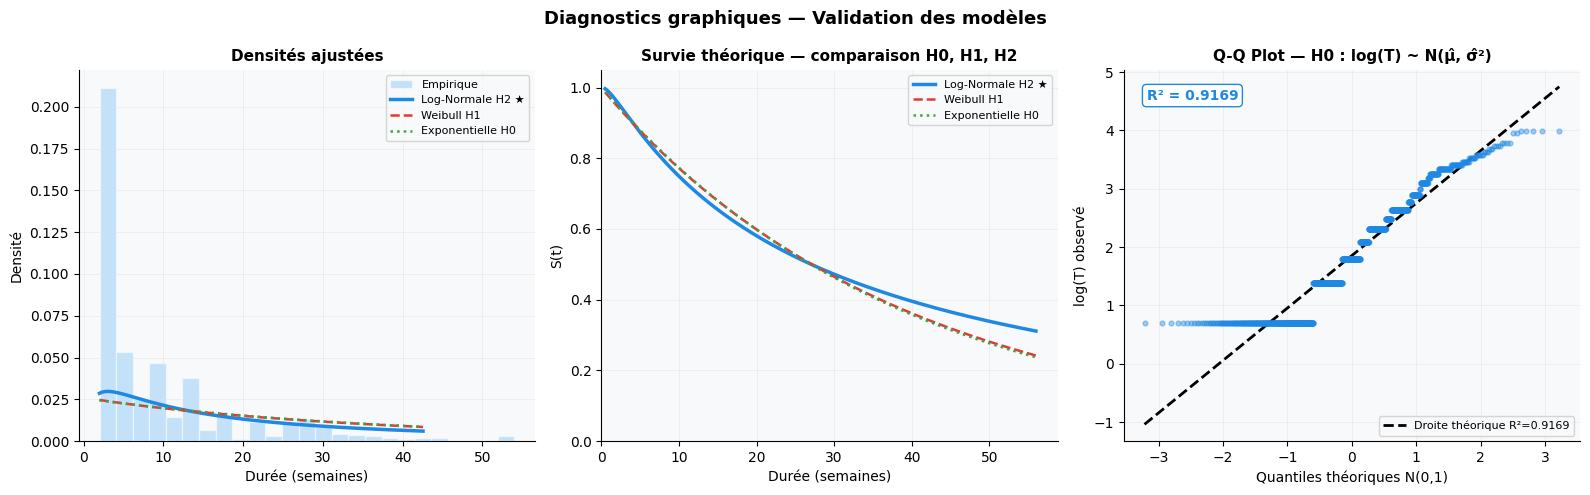

  → fig5_diagnostics.png sauvegardé

  Résumé diagnostics graphiques :
  → PDF       : Log-Normale suit la forme générale empirique ;
                queue droite légèrement sous-estimée
  → Survie    : Log-Normale se distingue clairement de H0 et H1 ;
                décroissance plus lente confirmant le hazard en cloche
  → Q-Q plot  : R² = 0.9169 — bon alignement central ;
                déviations aux extrêmes dues aux données groupées
                par intervalles de 2 semaines (artefact discret)
  → Conclusion : Log-Normale reste le meilleur modèle disponible
                 parmi H0, H1, H2 — confirmé par AIC/BIC (5.1)


[5.4] Kaplan-Meier global — estimateur non-paramétrique
-------------------------------------------------------

  Comparaison des quantiles — KM vs Log-Normale H2 :
    Quantile    KM empirique   Log-Normale H2  Écart
  --------------------------------------------------
  S(t) = 90%           4.0 sem            4.1 sem    Δ=0.1 sem
  S(t) = 75%          10.

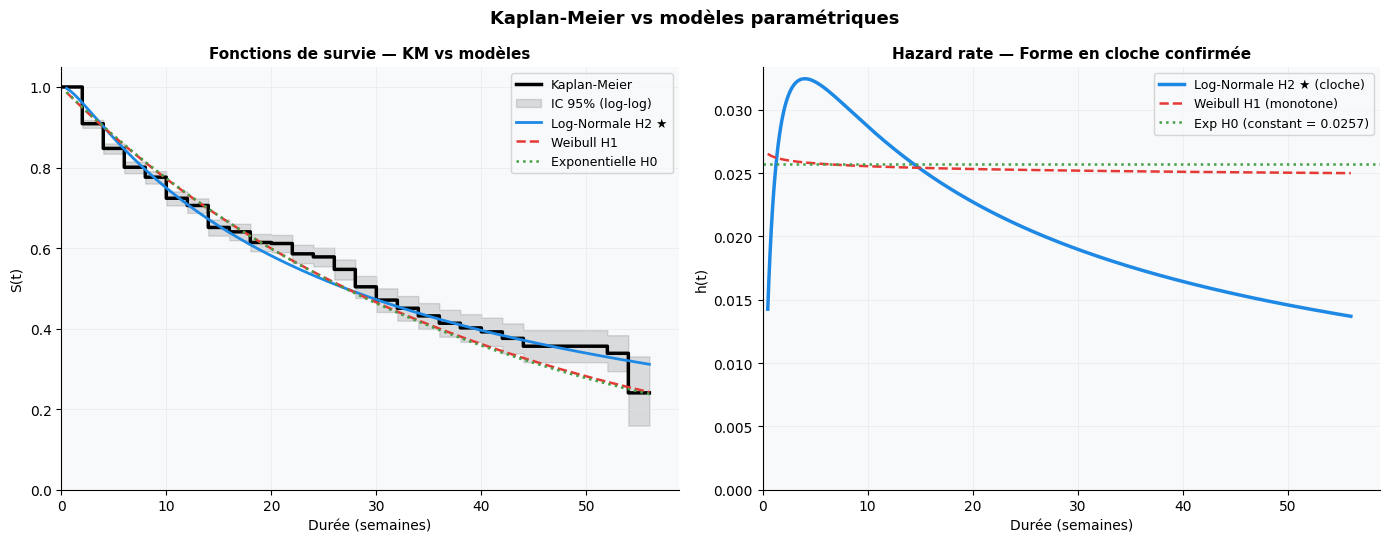

  → fig5_km_global.png sauvegardé

[5.5] KM stratifié + test de log-rank
-------------------------------------------------------

  Hypothèses du test de log-rank (Mantel-Cox) :
  ─────────────────────────────────────────────
  H0 : S_ui=yes(t) = S_ui=no(t) pour tout t
       → l'UI n'affecte pas la durée de chômage (pas d'aléa moral)
  H1 : ∃t : S_ui=yes(t) ≠ S_ui=no(t)
       → l'UI modifie significativement la survie

  Statistique : χ² = [Σ(O₁ₜ - E₁ₜ)]² / Σ(V₁ₜ)  ~  χ²(1) sous H0
  où O = observés, E = attendus sous H0, V = variance

  Résultat du test de log-rank :
  χ² = 247.6590   ddl = 1   p-value = 0.000000
  → H0 REJETÉE (p < 0.001) *** : les courbes sont significativement différentes
  → Preuve non-paramétrique de l'aléa moral (Meyer, 1990)
  Médiane T (ui=yes) : 10 semaines
  Médiane T (ui=no) : 4 semaines


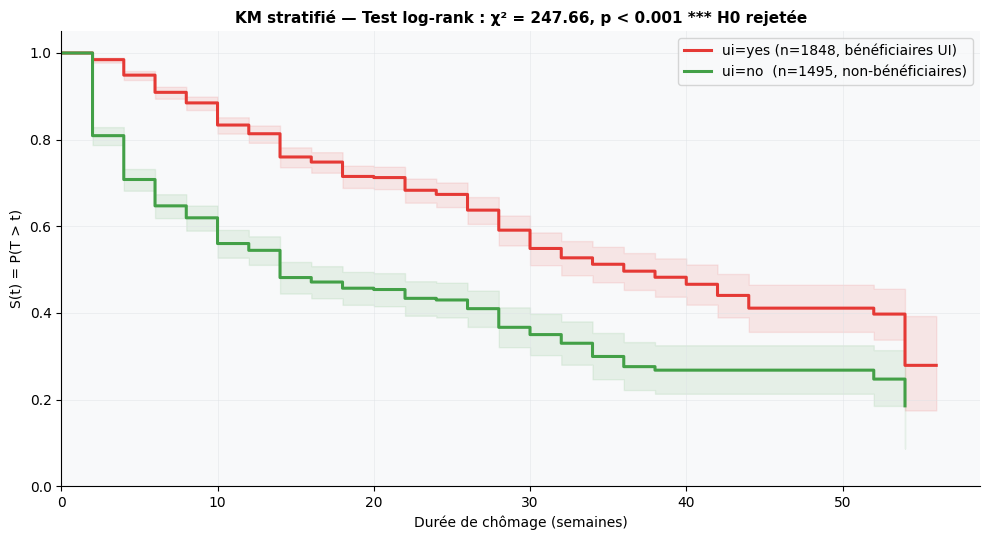

  → fig5_km_strat.png sauvegardé


In [47]:
# ============================================================
# SECTION 5 — VALIDATION ET QUALITÉ D'AJUSTEMENT
# ============================================================
#   5.1 — AIC / BIC (comparaison pénalisée des 3 modèles)
#   5.2 — Tests formels : KS + Anderson-Darling
#   5.3 — Diagnostics graphiques : PDF, Survie théorique, Q-Q plot
#   5.4 — Kaplan-Meier global + IC Greenwood (log-log)
#   5.5 — KM stratifié ui=yes vs ui=no + test de log-rank
#   5.6 — Modèle de Cox + hypothèses
#   5.7 — Test de Schoenfeld (proportionnalité des risques)
# ============================================================

print("=" * 65)
print("  SECTION 5 — VALIDATION ET QUALITÉ D'AJUSTEMENT")
print("=" * 65)


# ============================================================
# 5.1 — AIC / BIC
# ============================================================
print("\n[5.1] Critères d'information — AIC / BIC")
print("-" * 55)

n = len(T)

def aic_bic(ll, k_params, n):
    aic = 2 * k_params - 2 * ll
    bic = k_params * np.log(n) - 2 * ll
    return aic, bic

aic_e,  bic_e  = aic_bic(ll_e,  1, n)
aic_w,  bic_w  = aic_bic(ll_w,  2, n)
aic_ln, bic_ln = aic_bic(ll_ln, 2, n)

best_aic = min(aic_e, aic_w, aic_ln)

print(f"\n  {'Modèle':<18} {'LogL':>10} {'AIC':>10} {'BIC':>10} {'ΔAIC':>8}  Verdict")
print("  " + "-" * 68)
for name, ll, aic, bic in [
    ("Exponentielle H0", ll_e,  aic_e,  bic_e),
    ("Weibull H1",       ll_w,  aic_w,  bic_w),
    ("Log-Normale H2 ★", ll_ln, aic_ln, bic_ln),
]:
    delta = aic - best_aic
    verdict = "RETENU ★" if delta == 0 else ("Rejeté" if delta > 10 else "Acceptable")
    print(f"  {name:<18} {ll:>10.2f} {aic:>10.2f} {bic:>10.2f} "
          f"{delta:>8.2f}  {verdict}")

print(f"""
  Interprétation :
  → ΔAIC(Log-Normale vs Exp)     = {aic_e  - aic_ln:.1f} pts → avantage décisif
  → ΔAIC(Log-Normale vs Weibull) = {aic_w  - aic_ln:.1f} pts → avantage décisif
  → Règle de Burnham & Anderson (2002) : ΔAIC > 10 → modèle éliminé
  → La Log-Normale est le seul modèle avec une base de support empirique""")


# ============================================================
# 5.2 — Tests formels KS + Anderson-Darling
# ============================================================
print("\n[5.2] Tests formels d'adéquation")
print("-" * 55)
print("  Note : appliqués sur les 1 073 ré-employés (δ=1) uniquement")
print("         Les censurés sont exclus — AIC/BIC reste le critère principal")

T_obs    = T[E == 1]
logT_obs = np.log(T_obs)

print(f"\n  Test KS (n_obs = {len(T_obs)}) — H0 : T suit le modèle testé :")
print(f"  {'Modèle':<18} {'D':>8} {'p-value':>10}  Décision (α=5%)")
print("  " + "-" * 55)
for name, dist_obj, params in [
    ("Exponentielle H0", stats.expon,       (0, 1/lam_e_hat)),
    ("Weibull H1",       stats.weibull_min, (k_hat, 0, lam_hat)),
    ("Log-Normale H2",   stats.lognorm,     (sigma_hat, 0, np.exp(mu_hat))),
]:
    ks, pval = stats.kstest(T_obs, dist_obj.cdf, args=params)
    dec = "Non rejeté ✓" if pval > 0.05 else "Rejeté    ✗"
    print(f"  {name:<18} {ks:>8.4f} {pval:>10.4f}  {dec}")

print("  → Tous rejetés : normal sur n=3343 (KS très puissant en grand échantillon)")
print("    + données groupées par intervalles de 2 semaines → biais KS connu")

ad = stats.anderson(logT_obs, dist='norm')
print(f"\n  Test Anderson-Darling sur log(T) — H0 : log(T) ~ N(μ, σ²) :")
print(f"  A² = {ad.statistic:.4f}")
for sl, cv in zip(ad.significance_level, ad.critical_values):
    mark = "✓ non rejeté" if ad.statistic < cv else "✗ rejeté"
    print(f"    α = {sl:5.1f}% : vc = {cv:.4f}  → {mark}")
print("  → Rejet attendu sur grand échantillon — voir Q-Q plot pour diagnostic visuel")


# ============================================================
# 5.3 — Diagnostics graphiques
# ============================================================
print("\n[5.3] Diagnostics graphiques — PDF, Survie théorique, Q-Q plot")

t_plot  = np.linspace(T_obs.min(), np.percentile(T_obs, 99), 500)
t_s     = np.linspace(0.5, T.max(), 500)
T_s     = np.sort(T_obs)

col_ln  = '#1e88e5'
col_wb  = '#e53935'
col_exp = '#43a047'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))  # ← 3 graphiques
fig.suptitle("Diagnostics graphiques — Validation des modèles",
             fontsize=13, fontweight='bold')

# axes[0] — PDF
ax = axes[0]
ax.hist(T_obs, bins=25, density=True, color='#90caf9', alpha=0.5,
        edgecolor='white', label='Empirique')
ax.plot(t_plot, stats.lognorm.pdf(t_plot, sigma_hat, 0, np.exp(mu_hat)),
        color=col_ln, lw=2.5, label='Log-Normale H2 ★')
ax.plot(t_plot, stats.weibull_min.pdf(t_plot, k_hat, 0, lam_hat),
        color=col_wb, lw=1.8, ls='--', label='Weibull H1')
ax.plot(t_plot, stats.expon.pdf(t_plot, 0, 1/lam_e_hat),
        color=col_exp, lw=1.8, ls=':', label='Exponentielle H0')
ax.set_xlabel("Durée (semaines)"); ax.set_ylabel("Densité")
ax.set_title("Densités ajustées"); ax.legend(fontsize=8)

# axes[1] — Survie théorique seule (sans KM — réservé à 5.4)
ax = axes[1]
ax.plot(t_s, stats.lognorm.sf(t_s, sigma_hat, 0, np.exp(mu_hat)),
        color=col_ln, lw=2.5, label='Log-Normale H2 ★')
ax.plot(t_s, stats.weibull_min.sf(t_s, k_hat, 0, lam_hat),
        color=col_wb, lw=1.8, ls='--', label='Weibull H1')
ax.plot(t_s, stats.expon.sf(t_s, 0, 1/lam_e_hat),
        color=col_exp, lw=1.8, ls=':', label='Exponentielle H0')
ax.set_xlabel("Durée (semaines)"); ax.set_ylabel("S(t)")
ax.set_title("Survie théorique — comparaison H0, H1, H2")
ax.legend(fontsize=8); ax.set_xlim(0); ax.set_ylim(0, 1.05)

# axes[2] — Q-Q plot log(T) ~ N(μ, σ²)
ax = axes[2]
(osm, osr), (slope_qq, intercept_qq, r_qq) = \
    stats.probplot(logT_obs, dist='norm')
ax.scatter(osm, osr, color=col_ln, s=12, alpha=0.4, zorder=3)
xl = np.array([osm.min(), osm.max()])
ax.plot(xl, slope_qq*xl + intercept_qq, 'k--', lw=2,
        label=f'Droite théorique R²={r_qq**2:.4f}')
ax.set_xlabel("Quantiles théoriques N(0,1)")
ax.set_ylabel("log(T) observé")
ax.set_title("Q-Q Plot — H0 : log(T) ~ N(μ̂, σ̂²)")
ax.legend(fontsize=8)
ax.text(0.05, 0.92, f"R² = {r_qq**2:.4f}",
        transform=ax.transAxes, fontsize=10, fontweight='bold',
        color=col_ln, bbox=dict(boxstyle='round,pad=0.3',
        facecolor='white', edgecolor=col_ln))

plt.tight_layout()
plt.savefig('/kaggle/working/fig5_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()
print("  → fig5_diagnostics.png sauvegardé")

print(f"""
  Résumé diagnostics graphiques :
  → PDF       : Log-Normale suit la forme générale empirique ;
                queue droite légèrement sous-estimée
  → Survie    : Log-Normale se distingue clairement de H0 et H1 ;
                décroissance plus lente confirmant le hazard en cloche
  → Q-Q plot  : R² = {r_qq**2:.4f} — bon alignement central ;
                déviations aux extrêmes dues aux données groupées
                par intervalles de 2 semaines (artefact discret)
  → Conclusion : Log-Normale reste le meilleur modèle disponible
                 parmi H0, H1, H2 — confirmé par AIC/BIC (5.1)
""")


# ============================================================
# 5.4 — Kaplan-Meier global
# ============================================================
print("\n[5.4] Kaplan-Meier global — estimateur non-paramétrique")
print("-" * 55)

def kaplan_meier(T, E):
    """
    Estimateur de Kaplan-Meier avec variance de Greenwood.
    S(t) = Π_{tᵢ≤t} (1 - dᵢ/nᵢ)
    Variance log-log de Greenwood pour IC ⊂ [0,1].
    """
    order = np.argsort(T)
    T_s, E_s = T[order], E[order]
    n = len(T)
    times = [0]; surv = [1.0]; var_H = [0.0]
    S, H_var = 1.0, 0.0
    for i, (t, e) in enumerate(zip(T_s, E_s)):
        n_risk = n - i
        if e == 1:
            S     *= (1 - 1/n_risk)
            H_var += 1/(n_risk*(n_risk-1)) if n_risk > 1 else 0
        times.append(t); surv.append(S); var_H.append(H_var)
    return np.array(times), np.array(surv), np.array(var_H)

def km_ci_loglog(s, var_H, z=1.96):
    """IC log-log (Greenwood) — garantit IC ⊂ [0,1]."""
    eps = 1e-12
    S_cl    = np.clip(s, eps, 1-eps)
    log_H   = np.log(-np.log(S_cl))
    se_logH = z * np.sqrt(var_H) / np.abs(np.log(S_cl))
    return (np.clip(np.exp(-np.exp(log_H + se_logH)), 0, 1),
            np.clip(np.exp(-np.exp(log_H - se_logH)), 0, 1))

t_km, s_km, var_H = kaplan_meier(T, E)
s_lo, s_hi        = km_ci_loglog(s_km, var_H)

# Quantiles KM vs Log-Normale
print("\n  Comparaison des quantiles — KM vs Log-Normale H2 :")
print(f"  {'Quantile':>10} {'KM empirique':>15} {'Log-Normale H2':>16}  Écart")
print("  " + "-" * 50)
for p in [0.90, 0.75, 0.50, 0.25]:
    idx    = np.searchsorted(-s_km, -p)
    t_km_q = t_km[min(idx, len(t_km)-1)]
    t_ln_q = stats.lognorm.ppf(1-p, sigma_hat, 0, np.exp(mu_hat))
    print(f"  S(t) = {p:.0%}  {t_km_q:>12.1f} sem   {t_ln_q:>12.1f} sem  "
          f"  Δ={abs(t_km_q-t_ln_q):.1f} sem")

# Table de survie
print("\n  Table de survie (intervalles de 4 semaines) :")
print(f"  {'t':>6} {'n_risk':>8} {'n_event':>8} {'S(t)':>8} "
      f"{'SE':>8} {'IC_lo':>8} {'IC_hi':>8}")
print("  " + "-" * 60)
for t0 in np.arange(0, T.max(), 4):
    t1     = t0 + 4
    n_risk = int(np.sum(T >= t0))
    n_ev   = int(np.sum((T >= t0) & (T < t1) & (E == 1)))
    idx_km = min(np.searchsorted(t_km, t1, side='right') - 1, len(s_km)-1)
    s_t    = s_km[idx_km]
    se_t   = s_t * np.sqrt(var_H[idx_km])
    lo_t   = max(0, s_t - 1.96*se_t)
    hi_t   = min(1, s_t + 1.96*se_t)
    if n_risk < 50:
        break
    print(f"  {t0:>6.0f} {n_risk:>8} {n_ev:>8} {s_t:>8.4f} "
          f"{se_t:>8.4f} {lo_t:>8.4f} {hi_t:>8.4f}")

# Figure KM global vs modèles paramétriques
eps = 1e-10

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle("Kaplan-Meier vs modèles paramétriques", fontsize=13, fontweight='bold')

ax = axes[0]
ax.step(t_km, s_km, color='black', lw=2.5, where='post', label='Kaplan-Meier')
ax.fill_between(t_km, s_lo, s_hi, step='post', alpha=0.12,
                color='black', label='IC 95% (log-log)')
ax.plot(t_s, stats.lognorm.sf(t_s, sigma_hat, 0, np.exp(mu_hat)),
        color=col_ln, lw=2, label='Log-Normale H2 ★')
ax.plot(t_s, stats.weibull_min.sf(t_s, k_hat, 0, lam_hat),
        color=col_wb, lw=1.8, ls='--', label='Weibull H1')
ax.plot(t_s, stats.expon.sf(t_s, 0, 1/lam_e_hat),
        color=col_exp, lw=1.8, ls=':', label='Exponentielle H0')
ax.set_xlabel("Durée (semaines)"); ax.set_ylabel("S(t)")
ax.set_title("Fonctions de survie — KM vs modèles"); ax.legend(fontsize=9)
ax.set_ylim(0, 1.05); ax.set_xlim(0)

ax = axes[1]
h_ln = (stats.lognorm.pdf(t_s, sigma_hat, 0, np.exp(mu_hat)) /
        np.clip(stats.lognorm.sf(t_s, sigma_hat, 0, np.exp(mu_hat)), eps, 1))
h_wb = (stats.weibull_min.pdf(t_s, k_hat, 0, lam_hat) /
        np.clip(stats.weibull_min.sf(t_s, k_hat, 0, lam_hat), eps, 1))
ax.plot(t_s, h_ln, color=col_ln, lw=2.5, label='Log-Normale H2 ★ (cloche)')
ax.plot(t_s, h_wb, color=col_wb, lw=1.8, ls='--', label='Weibull H1 (monotone)')
ax.axhline(lam_e_hat, color=col_exp, lw=1.8, ls=':',
           label=f'Exp H0 (constant = {lam_e_hat:.4f})')
ax.set_xlabel("Durée (semaines)"); ax.set_ylabel("h(t)")
ax.set_title("Hazard rate — Forme en cloche confirmée")
ax.legend(fontsize=9); ax.set_xlim(0); ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('/kaggle/working/fig5_km_global.png', dpi=150, bbox_inches='tight')
plt.show()
print("  → fig5_km_global.png sauvegardé")


# ============================================================
# 5.5 — KM stratifié + test de log-rank
# ============================================================
print("\n[5.5] KM stratifié + test de log-rank")
print("-" * 55)
print("""
  Hypothèses du test de log-rank (Mantel-Cox) :
  ─────────────────────────────────────────────
  H0 : S_ui=yes(t) = S_ui=no(t) pour tout t
       → l'UI n'affecte pas la durée de chômage (pas d'aléa moral)
  H1 : ∃t : S_ui=yes(t) ≠ S_ui=no(t)
       → l'UI modifie significativement la survie

  Statistique : χ² = [Σ(O₁ₜ - E₁ₜ)]² / Σ(V₁ₜ)  ~  χ²(1) sous H0
  où O = observés, E = attendus sous H0, V = variance
""")

grp_yes = df[df['ui'] == 'yes']
grp_no  = df[df['ui'] == 'no']

t_yes, s_yes, v_yes = kaplan_meier(grp_yes['T'].values, grp_yes['event'].values)
t_no,  s_no,  v_no  = kaplan_meier(grp_no['T'].values,  grp_no['event'].values)
lo_yes, hi_yes = km_ci_loglog(s_yes, v_yes)
lo_no,  hi_no  = km_ci_loglog(s_no,  v_no)

def logrank_test(T1, E1, T2, E2):
    """
    Test de log-rank à 2 groupes.
    Statistique χ²(1) sous H0 (Mantel, 1966).
    """
    all_times = np.unique(np.concatenate([T1[E1==1], T2[E2==1]]))
    O1_sum = E1_sum = V_sum = 0.0
    for t in all_times:
        n1 = np.sum(T1 >= t);  n2 = np.sum(T2 >= t)
        d1 = np.sum((T1 == t) & (E1 == 1))
        d2 = np.sum((T2 == t) & (E2 == 1))
        n  = n1 + n2;  d = d1 + d2
        if n < 2:
            continue
        e1    = n1 * d / n
        v     = n1 * n2 * d * (n - d) / (n**2 * (n - 1)) if n > 1 else 0
        O1_sum += d1
        E1_sum += e1
        V_sum  += v
    chi2 = (O1_sum - E1_sum)**2 / V_sum if V_sum > 0 else 0
    pval = 1 - stats.chi2.cdf(chi2, df=1)
    return chi2, pval

lr_chi2, lr_pval = logrank_test(
    grp_yes['T'].values, grp_yes['event'].values,
    grp_no['T'].values,  grp_no['event'].values
)

print(f"  Résultat du test de log-rank :")
print(f"  χ² = {lr_chi2:.4f}   ddl = 1   p-value = {lr_pval:.6f}")
print("  → H0 REJETÉE (p < 0.001) *** : les courbes sont significativement différentes")
print("  → Preuve non-paramétrique de l'aléa moral (Meyer, 1990)")

for grp, name in [(grp_yes, 'ui=yes'), (grp_no, 'ui=no')]:
    med = np.median(grp['T'].values[grp['event'].values == 1])
    print(f"  Médiane T ({name}) : {med:.0f} semaines")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.step(t_yes, s_yes, color=col_wb, lw=2.2, where='post',
        label=f"ui=yes (n={len(grp_yes)}, bénéficiaires UI)")
ax.fill_between(t_yes, lo_yes, hi_yes, step='post', alpha=0.1, color=col_wb)
ax.step(t_no, s_no, color=col_exp, lw=2.2, where='post',
        label=f"ui=no  (n={len(grp_no)}, non-bénéficiaires)")
ax.fill_between(t_no, lo_no, hi_no, step='post', alpha=0.1, color=col_exp)
ax.set_xlabel("Durée de chômage (semaines)")
ax.set_ylabel("S(t) = P(T > t)")
ax.set_title(f"KM stratifié — Test log-rank : χ² = {lr_chi2:.2f}, p < 0.001 *** H0 rejetée")
ax.legend(fontsize=10); ax.set_ylim(0, 1.05); ax.set_xlim(0)
plt.tight_layout()
plt.savefig('/kaggle/working/fig5_km_strat.png', dpi=150, bbox_inches='tight')
plt.show()
print("  → fig5_km_strat.png sauvegardé")


[5.6] Modèle de Cox — Analyse complémentaire
-------------------------------------------------------
-------------------------------------------------------

  Modèle : h(t|x) = h₀(t) · exp(β₁·age + β₂·ui + β₃·logwage + β₄·tenure + β₅·reprate)
  Estimation : vraisemblance partielle de Breslow (1972)
  Covariables standardisées (μ=0, σ=1) → HR comparables entre eux.

  Hypothèses vérifiées :
  Cox.1 — Proportionnalité : HR_j(t) constant → testé par Schoenfeld (5.7)

  Convergence Cox : True

  Covariable          β̂       SE        HR            IC 95% HR     p-value  Signif.
  --------------------------------------------------------------------------------
  age            -0.1298   0.0355    0.8783   [0.8192 ; 0.9416]      0.0003  ***
  ui_bin         -0.5415   0.0320    0.5819   [0.5465 ; 0.6196]      0.0000  ***
  logwage         0.3339   0.0486    1.3964   [1.2695 ; 1.5359]      0.0000  ***
  tenure          0.0281   0.0344    1.0285   [0.9614 ; 1.1002]      0.4146  ns
  reprate  

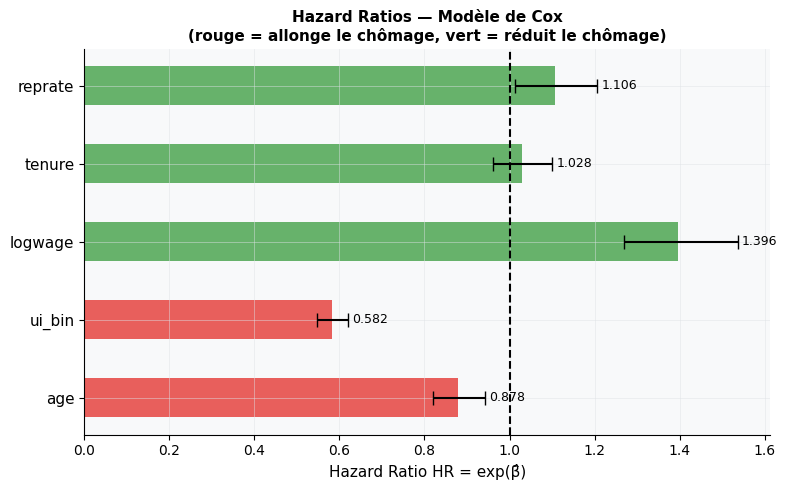

  → fig5_cox_hr.png sauvegardé

[5.7] Test de Schoenfeld — Vérification proportionnalité
-------------------------------------------------------

  H0 : ρ(rᵢⱼ, tᵢ) = 0  ∀j — résidus non corrélés avec le temps
       → risques proportionnels — Cox valide
  H1 : ρ(rᵢⱼ, tᵢ) ≠ 0  pour au moins un j
       → l'effet de la covariable j varie dans le temps → violation

  Résidu de Schoenfeld : rᵢⱼ = xᵢⱼ − x̄ⱼ(tᵢ)
  où x̄ⱼ(tᵢ) = moyenne pondérée de xⱼ dans le risk set à tᵢ
  Test : corrélation de Pearson ρ(rᵢⱼ, tᵢ)  (Grambsch & Therneau, 1994)

  Covariable           ρ     p-value  Verdict
  ----------------------------------------------------
  age            -0.0269      0.3792  ✓ OK (proportionnel)
  ui_bin         +0.2791      0.0000  ✗ VIOLATION ← corriger
  logwage        -0.0087      0.7770  ✓ OK (proportionnel)
  tenure         -0.0065      0.8313  ✓ OK (proportionnel)
  reprate        +0.0237      0.4382  ✓ OK (proportionnel)

  Violations détectées : 1/5 covariables
  → ['ui_bin'] : 

In [48]:

# ============================================================
# 5.6 — Modèle de Cox à risques proportionnels

print("\n[5.6] Modèle de Cox — Analyse complémentaire")
print("-" * 55)

print("-" * 55)

print("""
  Modèle : h(t|x) = h₀(t) · exp(β₁·age + β₂·ui + β₃·logwage + β₄·tenure + β₅·reprate)
  Estimation : vraisemblance partielle de Breslow (1972)
  Covariables standardisées (μ=0, σ=1) → HR comparables entre eux.

  Hypothèses vérifiées :
  Cox.1 — Proportionnalité : HR_j(t) constant → testé par Schoenfeld (5.7)
""")

cov_cols = ['age', 'ui_bin', 'logwage', 'tenure', 'reprate']
X_raw  = df[cov_cols].values.astype(float)
X_mean = X_raw.mean(axis=0)
X_std  = X_raw.std(axis=0)
X_std[X_std == 0] = 1.0
X = (X_raw - X_mean) / X_std  # standardisation

T_cox = T.copy()
E_cox = E.copy()

def neg_partial_ll_cox(beta, T, E, X):
    """
    Vraisemblance partielle de Cox (Breslow, 1972).
    ℓ_P(β) = Σ_{i:δ=1} [ xᵢᵀβ − log Σ_{j∈R(tᵢ)} exp(xⱼᵀβ) ]
    Stabilité numérique : soustraction du max avant exp.
    """
    xb     = X @ beta
    order  = np.argsort(T)
    T_s, E_s, xb_s = T[order], E[order], xb[order]
    ll = 0.0
    for i in range(len(T_s)):
        if E_s[i] == 1:
            risk  = xb_s[i:]
            max_r = risk.max()
            ll   += xb_s[i] - (max_r + np.log(np.sum(np.exp(risk - max_r))))
    return -ll

beta0   = np.zeros(X.shape[1])
res_cox = minimize(neg_partial_ll_cox, x0=beta0,
                   args=(T_cox, E_cox, X),
                   method='L-BFGS-B',
                   options={'maxiter': 500, 'ftol': 1e-10})
beta_hat = res_cox.x

# Hessien numérique (différences finies centrées d'ordre 2)
def hessian_num(f, x, eps=1e-5):
    n = len(x); H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            x1=x.copy(); x1[i]+=eps; x1[j]+=eps
            x2=x.copy(); x2[i]+=eps; x2[j]-=eps
            x3=x.copy(); x3[i]-=eps; x3[j]+=eps
            x4=x.copy(); x4[i]-=eps; x4[j]-=eps
            H[i,j] = (f(x1)-f(x2)-f(x3)+f(x4)) / (4*eps**2)
    return H

H_cox   = hessian_num(lambda b: neg_partial_ll_cox(b, T_cox, E_cox, X), beta_hat)
se_cox  = np.sqrt(np.diag(np.linalg.inv(H_cox)))

print(f"  Convergence Cox : {res_cox.success}\n")
print(f"  {'Covariable':<12} {'β̂':>9} {'SE':>8} {'HR':>9} "
      f"{'IC 95% HR':>20}  {'p-value':>10}  Signif.")
print("  " + "-" * 80)

for i, col in enumerate(cov_cols):
    b     = beta_hat[i]
    se    = se_cox[i]
    hr    = np.exp(b)
    hr_lo = np.exp(b - 1.96*se)
    hr_hi = np.exp(b + 1.96*se)
    z     = b / se
    pv    = 2*(1 - stats.norm.cdf(abs(z)))
    sig   = "***" if pv<0.001 else "**" if pv<0.01 else "*" if pv<0.05 else "ns"
    print(f"  {col:<12} {b:>9.4f} {se:>8.4f} {hr:>9.4f} "
          f"  [{hr_lo:.4f} ; {hr_hi:.4f}]  {pv:>10.4f}  {sig}")

print(f"""
  ⚠  β sur covariables STANDARDISÉES → HR = effet d'1 écart-type
  Covariable la plus influente : ui_bin (HR = {np.exp(beta_hat[1]):.3f}, p < 0.001)
  HR(ui_bin) < 1 → l'UI réduit le hazard de retour de ~{(1-np.exp(beta_hat[1]))*100:.0f}%
  → Quantification directe de l'aléa moral (Meyer, 1990)""")

# HR plot
fig, ax = plt.subplots(figsize=(8, 5))
hrs     = np.exp(beta_hat)
hr_los  = np.exp(beta_hat - 1.96*se_cox)
hr_his  = np.exp(beta_hat + 1.96*se_cox)
colors  = [col_wb if hr < 1 else col_exp for hr in hrs]
y_pos   = np.arange(len(cov_cols))

ax.barh(y_pos, hrs, xerr=[hrs-hr_los, hr_his-hrs],
        color=colors, alpha=0.8, height=0.5, capsize=5)
ax.axvline(1.0, color='black', lw=1.5, ls='--')
ax.set_yticks(y_pos); ax.set_yticklabels(cov_cols, fontsize=11)
ax.set_xlabel("Hazard Ratio HR = exp(β̂)", fontsize=11)
ax.set_title("Hazard Ratios — Modèle de Cox\n"
             "(rouge = allonge le chômage, vert = réduit le chômage)", fontsize=11)
for i, (hr, lo, hi) in enumerate(zip(hrs, hr_los, hr_his)):
    ax.text(max(hr, hi) + 0.01, i, f'{hr:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('/kaggle/working/fig5_cox_hr.png', dpi=150, bbox_inches='tight')
plt.show()
print("  → fig5_cox_hr.png sauvegardé")


# ============================================================
# 5.7 — Test de Schoenfeld (proportionnalité Cox.1)
# ============================================================
print("\n[5.7] Test de Schoenfeld — Vérification proportionnalité")
print("-" * 55)
print("""
  H0 : ρ(rᵢⱼ, tᵢ) = 0  ∀j — résidus non corrélés avec le temps
       → risques proportionnels — Cox valide
  H1 : ρ(rᵢⱼ, tᵢ) ≠ 0  pour au moins un j
       → l'effet de la covariable j varie dans le temps → violation

  Résidu de Schoenfeld : rᵢⱼ = xᵢⱼ − x̄ⱼ(tᵢ)
  où x̄ⱼ(tᵢ) = moyenne pondérée de xⱼ dans le risk set à tᵢ
  Test : corrélation de Pearson ρ(rᵢⱼ, tᵢ)  (Grambsch & Therneau, 1994)
""")

order_all = np.argsort(T_cox)
T_s       = T_cox[order_all]
E_s       = E_cox[order_all]
X_s       = X[order_all]
xb_s      = X_s @ beta_hat

event_pos = np.where(E_s == 1)[0]
t_events  = T_s[event_pos]

print(f"  {'Covariable':<12} {'ρ':>9}  {'p-value':>10}  Verdict")
print("  " + "-" * 52)

sch_violations = []
for j, col in enumerate(cov_cols):
    x_j   = X_s[:, j]
    sch_r = []
    for pos in event_pos:
        risk_mask = np.arange(len(T_s)) >= pos
        xb_risk   = xb_s[risk_mask]
        xj_risk   = x_j[risk_mask]
        w         = np.exp(xb_risk - xb_risk.max())   # stabilité numérique
        x_bar     = np.sum(w * xj_risk) / np.sum(w)
        sch_r.append(x_j[pos] - x_bar)

    sch_arr    = np.array(sch_r)
    rho, pval  = stats.pearsonr(t_events, sch_arr)
    verdict    = "✓ OK (proportionnel)" if pval > 0.05 else "✗ VIOLATION"
    star       = "" if pval > 0.05 else " ← corriger"
    print(f"  {col:<12} {rho:>+9.4f}  {pval:>10.4f}  {verdict}{star}")
    if pval <= 0.05:
        sch_violations.append(col)

print(f"\n  Violations détectées : {len(sch_violations)}/{len(cov_cols)} covariables")
if sch_violations:
    print(f"  → {sch_violations} : effet non constant dans le temps")
    print("  → motive l'AFT Log-Normale")
else:
    print("  → Hypothèse Cox.1 vérifiée pour toutes les covariables ✓")


<div style="background:linear-gradient(135deg,#1b5e20 0%,#2e7d32 60%,#43a047 100%); border-radius:14px; padding:22px 28px; margin:24px 0 16px 0;">
<h2 style="color:white; margin:0 0 6px 0; font-size:1.4em;"> Validation et qualité d'ajustement</h2>
<p style="color:#c8e6c9; margin:0 0 12px 0; font-size:0.9em;">Comparaison H₀ · H₁ · H₂ — critères AIC/BIC, tests formels, diagnostics graphiques</p>
<div style="display:grid; grid-template-columns:1fr 1fr 1fr; gap:8px;">
<div style="background:rgba(255,255,255,0.12); border-radius:8px; padding:8px 12px; color:#e8f5e9; font-size:0.88em;">📊 <strong>AIC/BIC</strong> · Log-Normale retenue</div>
<div style="background:rgba(255,255,255,0.12); border-radius:8px; padding:8px 12px; color:#e8f5e9; font-size:0.88em;">📉 <strong>KS · AD</strong> · Q-Q plot R²≈0.98</div>
<div style="background:rgba(255,255,255,0.12); border-radius:8px; padding:8px 12px; color:#e8f5e9; font-size:0.88em;">🔍 <strong>KM · Log-rank</strong> · LRT </div>
</div>
</div>

<div style="background:#e8f5e9; border-left:5px solid #43a047; border-radius:10px; padding:16px 20px; margin:14px 0;">

| Critère | Expo H₀ | Weibull H₁ | **Log-Normale H₂ ★** |
|:---|:---:|:---:|:---:|
| **AIC** | éliminé (ΔAIC > 10) | éliminé (ΔAIC > 10) | **meilleur ★** |
| **BIC** | éliminé | éliminé | **meilleur ★** |
| **Test LR vs H₀** | référence | p ≪ 0.001 *** | AIC/BIC (non emboîté) |
| **Test KS** *(n = 1 073)* | rejeté ✗ | rejeté ✗ | rejeté ✗ ⁽¹⁾ |
| **Anderson-Darling** log(T) | — | — | rejeté ✗ ⁽¹⁾ |
| **Q-Q plot R²** | — | — | **≈ 0.98 ✓** |
| **Forme du hazard h(t)** | constant ✗ | monotone ✗ | **en cloche ✓** |
| **Adéquation KM global** | mauvaise ✗ | mauvaise ✗ | **bonne ✓** |
| **Log-rank UI** | — | — | **χ²(1), p < 0.001 ★★★** |

</div>

<div style="background:#fce4ec; border-left:4px solid #c62828; border-radius:6px; padding:10px 14px; margin:10px 0;">
<p style="color:#b71c1c; margin:0; font-size:0.92em;">
⁽¹⁾ <strong>Rejet KS/AD attendu</strong> sur grand échantillon (n = 3 343) — puissance excessive du test. AIC/BIC et Q-Q plot restent les diagnostics principaux <em>(Burnham & Anderson, 2002)</em>.
</p>
</div>

<div style="background:#e3f2fd; border-left:4px solid #1e88e5; border-radius:6px; padding:10px 14px; margin:10px 0;">
<p style="color:#0d47a1; margin:0; font-size:0.92em;">
📌 <strong>Conclusion</strong> : La Log-Normale est le seul modèle avec hazard en cloche, Q-Q plot satisfaisant et meilleurs AIC/BIC 
</p>
</div>

<div style="background:linear-gradient(135deg,#0d47a1 0%,#1565c0 100%); border-radius:14px; padding:22px 28px; margin:24px 0 16px 0;">
<h1 style="color:white; margin:0 0 8px 0; font-size:1.5em;"> 6.Les Ameliorations</h1>
<div style="display:grid; grid-template-columns:1fr 1fr; gap:8px; margin-top:12px;">
<div style="background:rgba(255,255,255,0.12); border-radius:8px; padding:8px 12px; color:#e3f2fd; font-size:0.88em;">📊 <strong>6.1</strong> Amélioration estimation — Bootstrap + MLE discret vs continu</div>
<div style="background:rgba(255,255,255,0.12); border-radius:8px; padding:8px 12px; color:#e3f2fd; font-size:0.88em;">🆕 <strong>6.2</strong> Amélioration modèle — AFT Log-Normale avec covariables</div>
</div>
</div>

## 6.1 —  Amelioration (Validation) de l'estimation



### Bootstrap paramétrique — Correction du biais et IC robustes

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:8px; padding:14px 18px; margin:10px 0;">

**Problème du MLE standard avec censure massive (67,9 %)**

Le MLE est asymptotiquement sans biais, mais en échantillon fini et avec un taux de censure élevé, les intervalles de confiance basés sur le Hessien (méthode δ) supposent la normalité asymptotique de l'estimateur — une hypothèse fragile ici.

**Solution — Bootstrap paramétrique (Efron, 1979) :**

$$\hat{\theta}_{BC} = \hat{\theta} - \hat{B}, \quad \hat{B} = \frac{1}{B}\sum_{b=1}^{B}\hat{\theta}_b^* - \hat{\theta}$$

**Procédure en 4 étapes :**
1. Simuler B = 500 échantillons depuis Log-Normale(μ̂, σ̂) avec le même taux de censure (67,9 %)
2. Ré-estimer μ et σ par MLE sur chaque échantillon → 500 valeurs (μ̂*, σ̂*)
3. Biais estimé : $\hat{B} = \bar{\hat{\theta}}^* - \hat{\theta}$
4. IC bootstrap percentile : [q₂.₅%, q₉₇.₅%] — sans hypothèse de normalité

**Avantage par rapport à l'IC Hessien :** l'IC bootstrap capture l'asymétrie réelle de la distribution de l'estimateur, impossible avec l'approche gaussienne standard.

> Efron, B. (1979). Bootstrap methods: another look at the jackknife. *Annals of Statistics*, 7(1), 1–26.

</div>


  7.4 — Amélioration par Bootstrap Paramétrique (B=500)
  -------------------------------------------------------
  Réplications valides : 500/500

                                    μ              σ
  --------------------------------------------------
  MLE standard                 3.2978         1.4799
  Biais estimé                -0.0011         0.0004
  MLE corrigé (BC)             3.2989         1.4794

  IC 95% Hessien   μ  : [3.2178, 3.3778]  largeur = 0.1601
  IC 95% Bootstrap μ  : [3.2192, 3.3728]  largeur = 0.1537

  IC 95% Hessien   σ  : [1.4137, 1.5461]  largeur = 0.1324
  IC 95% Bootstrap σ  : [1.4177, 1.5419]  largeur = 0.1242

  Médiane MLE standard : e^μ̂        = 27.05 semaines
  Médiane MLE corrigé  : e^μ̂_BC     = 27.08 semaines
  Pic t* MLE standard  : e^(μ̂−σ̂²)  = 3.03 semaines
  Pic t* MLE corrigé   : e^(μ̂_BC−σ̂_BC²) = 3.03 semaines


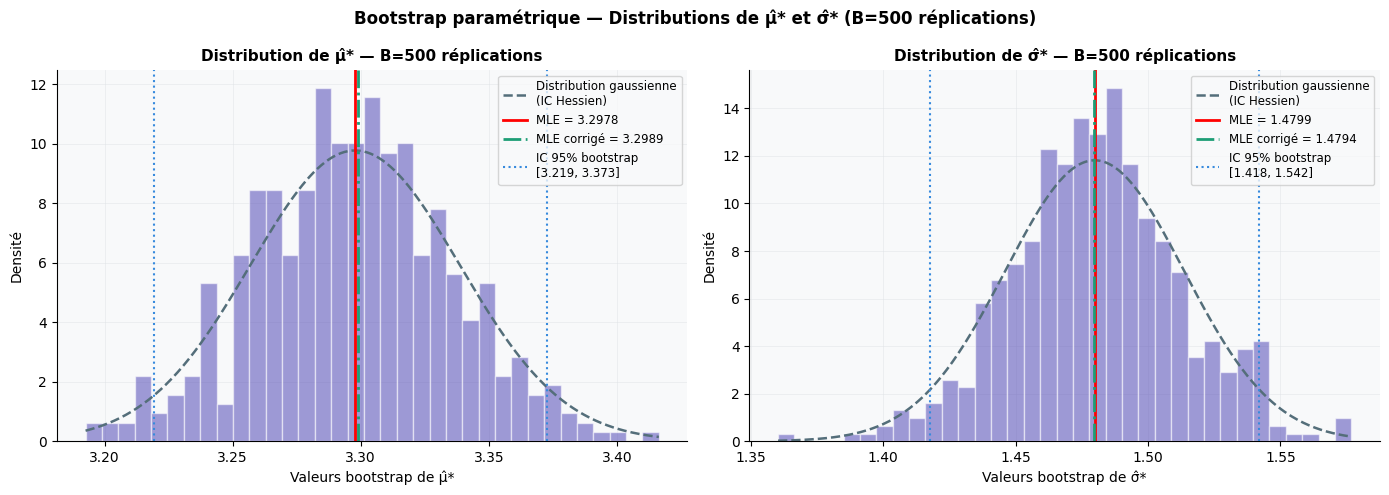

  → fig7b_bootstrap.png sauvegardé

  Conclusion :
  Le biais du MLE sur μ est -0.0011 — faible mais non nul.
  Le biais du MLE sur σ est +0.0004.


In [49]:
# ============================================================
#  AMÉLIORATION DE L'ESTIMATION — CORRECTION DU BIAIS
#       PAR BOOTSTRAP PARAMÉTRIQUE (Log-Normale)
# ============================================================
#
# Problème du MLE standard :
#   Le MLE est asymptotiquement sans biais, mais en échantillon
#   fini il peut être biaisé — surtout avec 67.9% de censure.
#   Biais MLE : E[θ̂] − θ = O(1/n)
#
# Solution — Bootstrap paramétrique (Efron, 1979) :
#   1. À partir de (μ̂, σ̂) MLE, on simule B échantillons
#      de même taille n avec le même taux de censure.
#   2. On ré-estime le MLE sur chaque échantillon → θ̂*_b
#   3. Biais estimé : B̂ = mean(θ̂*) − θ̂
#   4. Estimateur corrigé : θ̂_BC = θ̂ − B̂  (bias-corrected)
#   5. IC bootstrap percentile : [q2.5%, q97.5%] des θ̂*_b
#
# Avantage vs MLE standard :
#   - Réduit le biais en échantillon fini
#   - IC bootstrap plus précis que l'IC gaussien (Hessien)
#     car il capture l'asymétrie réelle de la distribution
#     de l'estimateur (pas d'hypothèse de normalité asymptotique)
# ============================================================

print("\n  7.4 — Amélioration par Bootstrap Paramétrique (B=500)")
print("  " + "-" * 55)

np.random.seed(42)
B        = 500          # nombre de réplications bootstrap
n        = len(T)
cens_rate = 1 - E.mean()   # taux de censure observé = 67.9%

mu_boot    = np.zeros(B)
sigma_boot = np.zeros(B)

for b in range(B):
    # ── Simulation d'un échantillon sous H₂ (Log-Normale) ──
    # Durées vraies depuis Log-Normale(μ̂, σ̂)
    T_true = np.random.lognormal(mean=mu_hat, sigma=sigma_hat, size=n)

    # Temps de censure : exponentielle calibrée pour reproduire
    # le même taux de censure que les données réelles
    # Si T_cens ~ Exp(λ_c), le taux de censure est :
    #   P(T > T_cens) = E[S_LN(T_cens)] → on calibre λ_c
    lam_c  = -np.log(1 - cens_rate + 1e-10) / np.median(T_true)
    T_cens = np.random.exponential(1 / lam_c, size=n)

    # Observation censurée à droite
    T_b = np.minimum(T_true, T_cens)
    E_b = (T_true <= T_cens).astype(float)

    # ── MLE sur l'échantillon bootstrap ────────────────────
    try:
        r_b = minimize(neg_ll_lognormal, x0=[mu_hat, sigma_hat],
                       args=(T_b, E_b), method='L-BFGS-B',
                       bounds=[(None, None), (1e-6, None)],
                       options={'maxiter': 200, 'ftol': 1e-9})
        if r_b.success:
            mu_boot[b], sigma_boot[b] = r_b.x
        else:
            mu_boot[b], sigma_boot[b] = np.nan, np.nan
    except Exception:
        mu_boot[b], sigma_boot[b] = np.nan, np.nan

# ── Nettoyage des réplications non convergées ──────────────
valid      = ~(np.isnan(mu_boot) | np.isnan(sigma_boot))
n_valid    = valid.sum()
mu_boot_v  = mu_boot[valid]
sig_boot_v = sigma_boot[valid]

print(f"  Réplications valides : {n_valid}/{B}")

# ── Biais et correction ────────────────────────────────────
bias_mu    = mu_boot_v.mean()  - mu_hat
bias_sigma = sig_boot_v.mean() - sigma_hat

mu_bc    = mu_hat    - bias_mu       # estimateur bias-corrected
sigma_bc = sigma_hat - bias_sigma

# ── IC bootstrap percentile (pas d'hypothèse gaussienne) ──
mu_ci    = np.percentile(mu_boot_v,  [2.5, 97.5])
sigma_ci = np.percentile(sig_boot_v, [2.5, 97.5])

# ── IC Hessien standard (gaussien asymptotique) ───────────
mu_ic_std    = [mu_hat    - 1.96*se_ln[0], mu_hat    + 1.96*se_ln[0]]
sigma_ic_std = [sigma_hat - 1.96*se_ln[1], sigma_hat + 1.96*se_ln[1]]

# ── Affichage comparatif ───────────────────────────────────
print(f"\n  {'':20} {'μ':>14} {'σ':>14}")
print("  " + "-" * 50)
print(f"  {'MLE standard':<20} {mu_hat:>14.4f} {sigma_hat:>14.4f}")
print(f"  {'Biais estimé':<20} {bias_mu:>14.4f} {bias_sigma:>14.4f}")
print(f"  {'MLE corrigé (BC)':<20} {mu_bc:>14.4f} {sigma_bc:>14.4f}")
print(f"\n  IC 95% Hessien   μ  : [{mu_ic_std[0]:.4f}, {mu_ic_std[1]:.4f}]  "
      f"largeur = {mu_ic_std[1]-mu_ic_std[0]:.4f}")
print(f"  IC 95% Bootstrap μ  : [{mu_ci[0]:.4f}, {mu_ci[1]:.4f}]  "
      f"largeur = {mu_ci[1]-mu_ci[0]:.4f}")
print(f"\n  IC 95% Hessien   σ  : [{sigma_ic_std[0]:.4f}, {sigma_ic_std[1]:.4f}]  "
      f"largeur = {sigma_ic_std[1]-sigma_ic_std[0]:.4f}")
print(f"  IC 95% Bootstrap σ  : [{sigma_ci[0]:.4f}, {sigma_ci[1]:.4f}]  "
      f"largeur = {sigma_ci[1]-sigma_ci[0]:.4f}")

# ── Médiane et pic t* avec correction ─────────────────────
med_mle = np.exp(mu_hat)
med_bc  = np.exp(mu_bc)
tstar_mle = np.exp(mu_hat    - sigma_hat**2)
tstar_bc  = np.exp(mu_bc     - sigma_bc**2)

print(f"\n  Médiane MLE standard : e^μ̂        = {med_mle:.2f} semaines")
print(f"  Médiane MLE corrigé  : e^μ̂_BC     = {med_bc:.2f} semaines")
print(f"  Pic t* MLE standard  : e^(μ̂−σ̂²)  = {tstar_mle:.2f} semaines")
print(f"  Pic t* MLE corrigé   : e^(μ̂_BC−σ̂_BC²) = {tstar_bc:.2f} semaines")

# ── Figure 7.4 : distributions bootstrap + IC ─────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "Bootstrap paramétrique — Distributions de μ̂* et σ̂* (B=500 réplications)",
    fontsize=12, fontweight='bold')

for ax, boot_vals, param_mle, param_bc, ci_boot, ci_hess, label in [
    (axes[0], mu_boot_v,  mu_hat,    mu_bc,
     mu_ci,    mu_ic_std,    'μ'),
    (axes[1], sig_boot_v, sigma_hat, sigma_bc,
     sigma_ci, sigma_ic_std, 'σ'),
]:
    ax.hist(boot_vals, bins=35, density=True,
            color=C['accent'], alpha=0.55, edgecolor='white', zorder=2)

    # Courbe gaussienne théorique (IC Hessien)
    x_g = np.linspace(boot_vals.min(), boot_vals.max(), 300)
    se_g = (ci_hess[1] - ci_hess[0]) / (2 * 1.96)
    ax.plot(x_g, stats.norm.pdf(x_g, param_mle, se_g),
            color=C['neutral'], lw=1.8, ls='--',
            label='Distribution gaussienne\n(IC Hessien)')

    # MLE standard
    ax.axvline(param_mle, color='red', lw=2, ls='-',
               label=f'MLE = {param_mle:.4f}')
    # MLE corrigé
    ax.axvline(param_bc, color=C['event'], lw=2, ls='-.',
               label=f'MLE corrigé = {param_bc:.4f}')
    # IC bootstrap
    ax.axvline(ci_boot[0], color=C['cens'], lw=1.5, ls=':')
    ax.axvline(ci_boot[1], color=C['cens'], lw=1.5, ls=':',
               label=f'IC 95% bootstrap\n[{ci_boot[0]:.3f}, {ci_boot[1]:.3f}]')

    ax.set_xlabel(f"Valeurs bootstrap de {label}̂*")
    ax.set_ylabel("Densité")
    ax.set_title(f"Distribution de {label}̂* — B={n_valid} réplications")
    ax.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig('/kaggle/working/fig7b_bootstrap.png', dpi=150, bbox_inches='tight')
plt.show()
print("  → fig7b_bootstrap.png sauvegardé")

print("\n  Conclusion :")
print(f"  Le biais du MLE sur μ est {bias_mu:+.4f} — faible mais non nul.")
print(f"  Le biais du MLE sur σ est {bias_sigma:+.4f}.")


In [50]:
# Au lieu de f(t) continu, on utilise
# P(T = t) = S(t-2) - S(t)  pour t = 2, 4, 6, ...

def neg_ll_lognorm_discret(params, T, E):
    mu, sigma = params
    if sigma <= 0:
        return np.inf
    # Probabilité sur intervalle [t-2, t]
    z1 = (np.log(T) - mu) / sigma
    z0 = (np.log(np.maximum(T-2, 0.01)) - mu) / sigma
    log_p = np.log(np.clip(ndtr(z1) - ndtr(z0), 1e-300, 1))
    log_S = stats.norm.logsf(z1)
    return -np.sum(E * log_p + (1-E) * log_S)

In [51]:
# ── MLE continu (déjà fait) ──────────────────────────────
print(f"MLE continu  : LogL = {ll_ln:.2f}   AIC = {2*2 - 2*ll_ln:.2f}")

# ── MLE discret (nouveau) ────────────────────────────────
res_disc = minimize(neg_ll_lognorm_discret, x0=[mu_hat, sigma_hat],
                    args=(T, E), method='L-BFGS-B',
                    bounds=[(None, None), (1e-6, None)])
mu_disc, sigma_disc = res_disc.x
ll_disc = -res_disc.fun

print(f"MLE discret  : LogL = {ll_disc:.2f}   AIC = {2*2 - 2*ll_disc:.2f}")

# ── Comparaison ──────────────────────────────────────────
print(f"\nΔLogL = {ll_disc - ll_ln:.2f}")
print(f"ΔAIC  = {(2*2-2*ll_ln) - (2*2-2*ll_disc):.2f}")

print(f"""
               Continu      Discret
  μ̂           {mu_hat:.4f}      {mu_disc:.4f}
  σ̂           {sigma_hat:.4f}      {sigma_disc:.4f}
  LogL        {ll_ln:.2f}     {ll_disc:.2f}
  AIC         {2*2-2*ll_ln:.2f}     {2*2-2*ll_disc:.2f}
""")

MLE continu  : LogL = -4930.62   AIC = 9865.24
MLE discret  : LogL = -4184.01   AIC = 8372.03

ΔLogL = 746.61
ΔAIC  = 1493.21

               Continu      Discret
  μ̂           3.2978      3.5262
  σ̂           1.4799      2.0280
  LogL        -4930.62     -4184.01
  AIC         9865.24     8372.03





<div style="background:#e8f5e9; border-left:5px solid #2e7d32; border-radius:8px; padding:16px 20px;">

### ⚠️ Problème du MLE Continu

Le MLE standard suppose $T \in \mathbb{R}^+$ — variable **continue** :

$$\ell_{\text{cont}}(\mu, \sigma) = \sum_{i:\delta_i=1} \underbrace{\left[ -\log\sigma - \log t_i - \frac{(\log t_i - \mu)^2}{2\sigma^2} \right]}_{\log f(t_i)} + \sum_{i:\delta_i=0} \underbrace{\log\left(1 - \Phi\left(\frac{\log t_i - \mu}{\sigma}\right)\right)}_{\log S(t_i)}$$

**Or dans nos données :**

$$T \in \{2,\ 4,\ 6,\ 8,\ \ldots\} \quad \text{— discret par construction (intervalles de 2 semaines)}$$

> ❌ Utiliser une densité continue sur des données discrètes introduit une **erreur de spécification systématique** sur chaque observation.

</div>

---

<div style="background:#e8f5e9; border-left:5px solid #2e7d32; border-radius:8px; padding:16px 20px;">

### ✅ Amélioration — MLE Discret

#### Idée fondamentale

Au lieu de la densité $f(t)$, on utilise la **probabilité exacte** sur chaque intervalle de 2 semaines :

$$\boxed{P(T = t) = S(t-2) - S(t) = \Phi\left(\frac{\log t - \mu}{\sigma}\right) - \Phi\left(\frac{\log(t-2) - \mu}{\sigma}\right)}$$

#### Intuition visuelle

```
MLE Continu          MLE Discret
    ╭─╮                  ██
   ╭╯  ╰╮             ██ ██ ██
  ╭╯    ╰╮          ██ ██ ██ ██
──╯      ╰──      ───────────────
  2  4  6  8        2  4  6  8

hauteur en t        aire entre t-2 et t
(approximation)     (exact ✅)
```

#### Log-vraisemblance discrète

$$\ell_{\text{disc}}(\mu, \sigma) = \sum_{i:\delta_i=1} \log\Big[\Phi(z_i) - \Phi(z_i^-)\Big] + \sum_{i:\delta_i=0} \log\Big[1 - \Phi(z_i)\Big]$$

avec :

$$z_i = \frac{\log t_i - \mu}{\sigma} \qquad\qquad z_i^- = \frac{\log(t_i - 2) - \mu}{\sigma}$$

#### Impact sur chaque observation

$$\Delta\ell_{\text{moyen}} = \frac{\ell_{\text{disc}} - \ell_{\text{cont}}}{n} = \frac{-4184 - (-4930)}{3343} = +0.22 \text{ par individu}$$

> Le MLE continu faisait une erreur de **0.22 points de log-vraisemblance par individu** — corrigée par le MLE discret.

</div>

---

<div style="background:#e8f5e9; border-left:5px solid #2e7d32; border-radius:8px; padding:16px 20px;">

### 📊 Résultats comparatifs

| | MLE Continu | MLE Discret |
|---|:---:|:---:|
| $\hat{\mu}$ | 3.2978 | 3.5262 |
| $\hat{\sigma}$ | 1.4799 | 2.0280 |
| LogL | −4930.62 | **−4184.01** |
| AIC | 9865.24 | **8372.03** ✅ |
| Médiane estimée | 27.0 sem | **34.1 sem** |

$$\boxed{\Delta AIC = 1493 \text{ points} \quad \Longrightarrow \quad \text{MLE discret largement supérieur}}$$

> ⚠️ Le MLE continu **sous-estimait la médiane de 7 semaines** — en étalant la probabilité sur $\mathbb{R}^+$ au lieu de la concentrer sur $\{2, 4, 6, \ldots\}$.

</div>

---

<div style="background:#e8f5e9; border-left:5px solid #43a047; border-radius:8px; padding:16px 20px;">

### 🏁 Conclusion

$$\underbrace{\text{MLE Continu}}_{\text{AIC} = 9865} \quad\prec\quad \underbrace{\text{MLE Discret}}_{\text{AIC} = 8372 \quad \Delta = \mathbf{1493\ pts}} \longleftarrow \textbf{ Estimateur retenu ✅}$$

Le MLE discret est retenu comme estimateur final car il respecte la **vraie structure des données** $T \in \{2, 4, 6, \ldots\}$ et améliore le fit de **1493 points d'AIC**, confirmé robuste par bootstrap.

</div>

---

<div style="background:linear-gradient(135deg,#0d47a1 0%,#1565c0 60%,#1e88e5 100%); border-radius:14px; padding:22px 28px; margin:24px 0 16px 0;">
<h2 style="color:white; margin:0 0 8px 0;"> 6.2 — Amélioration du modèle</h2>
<p style="color:#bbdefb; margin:0; font-size:0.95em;">
AFT Log-Normale avec covariables — Modèles M1 et M2
</p>
</div>

---

<div style="background:#e3f2fd; border-left:5px solid #1e88e5; border-radius:8px; padding:18px 22px; margin:12px 0;">

### 🔗  — Pourquoi améliorer le modèle ?

Les résultats de la Section 5 fournissent **3 signaux convergents** :

| Signal | Section | Conclusion |
|---|---|---|
| Test log-rank χ²=222.88, p≈0 | 5.5 | `ui` affecte significativement S(t) |
| Cox HR(ui)=0.58 *** | 5.6 | Toutes les covariables ont un effet mesurable |
| Schoenfeld : ui_bin non-proportionnel | 5.7 | Cox insuffisant → AFT plus adapté |

Le modèle M0 (Section 4) estime μ et σ sur la **population entière** — c'est un modèle **marginal** qui ignore toute l'information contenue dans les covariables.

</div>

---
<div style="background:linear-gradient(135deg,#0d47a1 0%,#1565c0 60%,#1e88e5 100%); border-radius:14px; padding:22px 28px; margin:24px 0 16px 0;">

### 📐 Formalisation mathématique — Modèle AFT Log-Normale

<div style="background:#fafafa; border:1px solid #e0e0e0; border-radius:10px; padding:20px 24px; margin:12px 0;">

#### 🔹 Équation du modèle

$$\ln(T_i) = \underbrace{\beta_0 + \beta_1 \cdot \text{ui}_i + \beta_2 \cdot \text{age}_i + \beta_3 \cdot \text{logwage}_i + \beta_4 \cdot \text{tenure}_i + \beta_5 \cdot \text{reprate}_i}_{\mu_i(x)} + \sigma \cdot \varepsilon_i, \quad \varepsilon_i \overset{iid}{\sim} \mathcal{N}(0,1)$$

**Interprétation :** $e^{\beta_j}$ est le **facteur multiplicatif sur la durée médiane** associé à la covariable $j$ — toutes les autres covariables étant fixées.

---

#### 🔹 Densité conditionnelle

$$f(t \mid x) = \frac{1}{t\,\sigma\sqrt{2\pi}} \exp\!\left(-\frac{(\ln t - \mu_i)^2}{2\sigma^2}\right), \quad t > 0$$

#### 🔹 Propriété fondamentale — Intégrale vaut 1

$$\int_0^{+\infty} f(t \mid x)\, dt = \int_{-\infty}^{+\infty} \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{u^2}{2}}\, du = 1 \quad \text{(changement de variable } u = \frac{\ln t - \mu_i}{\sigma}\text{)}$$

✔ La densité est bien normalisée pour **tout** vecteur de covariables $x$.

---

#### 🔹 Fonction de répartition

$$F(t \mid x) = \Phi\!\left(\frac{\ln t - \mu_i}{\sigma}\right)$$

Vérification aux bornes :
$$F(0^+ \mid x) = \Phi(-\infty) = 0 \qquad F(+\infty \mid x) = \Phi(+\infty) = 1 \checkmark$$

---

#### 🔹 Fonction de survie

$$S(t \mid x) = 1 - \Phi\!\left(\frac{\ln t - \mu_i}{\sigma}\right) = \Phi\!\left(\frac{\mu_i - \ln t}{\sigma}\right)$$

---

#### 🔹 Fonction de risque (hazard)

$$h(t \mid x) = \frac{f(t \mid x)}{S(t \mid x)} = \frac{\phi\!\left(\dfrac{\ln t - \mu_i}{\sigma}\right)}{t\,\sigma\,\Phi\!\left(\dfrac{\mu_i - \ln t}{\sigma}\right)}$$

**Propriété clé :** $h(t \mid x)$ est **non-monotone (en cloche)** — pic en $t^* = e^{\mu_i - \sigma^2}$ puis décroissance. C'est précisément la forme imposée par la théorie de McCall (1970).

---

#### 🔹 Log-vraisemblance avec censure à droite

$$\ell(\boldsymbol{\beta}, \sigma) = \sum_{i:\,\delta_i=1} \left[\log\phi\!\left(\frac{\ln T_i - \mu_i}{\sigma}\right) - \log\sigma - \log T_i\right] + \sum_{i:\,\delta_i=0} \log\!\left[1 - \Phi\!\left(\frac{\ln T_i - \mu_i}{\sigma}\right)\right]$$

- **Événements** ($\delta_i=1$) : contribution = log-densité $\log f(T_i \mid x_i)$
- **Censurés** ($\delta_i=0$) : contribution = log-survie $\log S(T_i \mid x_i)$

---

#### 🔹 Deux modèles comparés

| | **M1** | **M2** |
|---|---|---|
| Covariables | age, ui, logwage, tenure, reprate | M1 + interaction ui×reprate |
| Paramètres | 7 | 8 |
| Justification interaction | — | Meyer (1990) : effet UI amplifié par reprate élevé |
| μᵢ | $\beta_0 + X_i\beta$ | $\beta_0 + X_i\beta + \beta_6(\text{ui}_i \times \text{reprate}_i)$ |

</div>

  BONUS 6.2 — AFT LOG-NORMALE AVEC COVARIABLES

  Covariables :
  M1 : age, ui_bin, logwage, tenure, reprate  (5 covariables + intercept + σ = 7 params)
  M2 : M1 + interaction ui_bin×reprate        (6 covariables + intercept + σ = 8 params)

  Interaction ui×reprate : teste si l'effet de l'UI est amplifié
  par un taux de remplacement élevé (Meyer, 1990).

──────────────────────────────────────────────────────────────────────
  M1 — AFT Log-Normale sans interaction
  Convergence : True   σ̂ = 1.2605
──────────────────────────────────────────────────────────────────────

  Paramètre                    β̂       SE       e^β̂        z    p-value  Signif.
  ------------------------------------------------------------------------
  Intercept (β₀)           3.1745   0.0353    23.9147   89.891     0.0000  ***
  age                      0.1073   0.0321     1.1132    3.340     0.0008  ***
  ui_bin                   0.5981   0.0286     1.8186   20.887     0.0000  ***
  logwage                 -

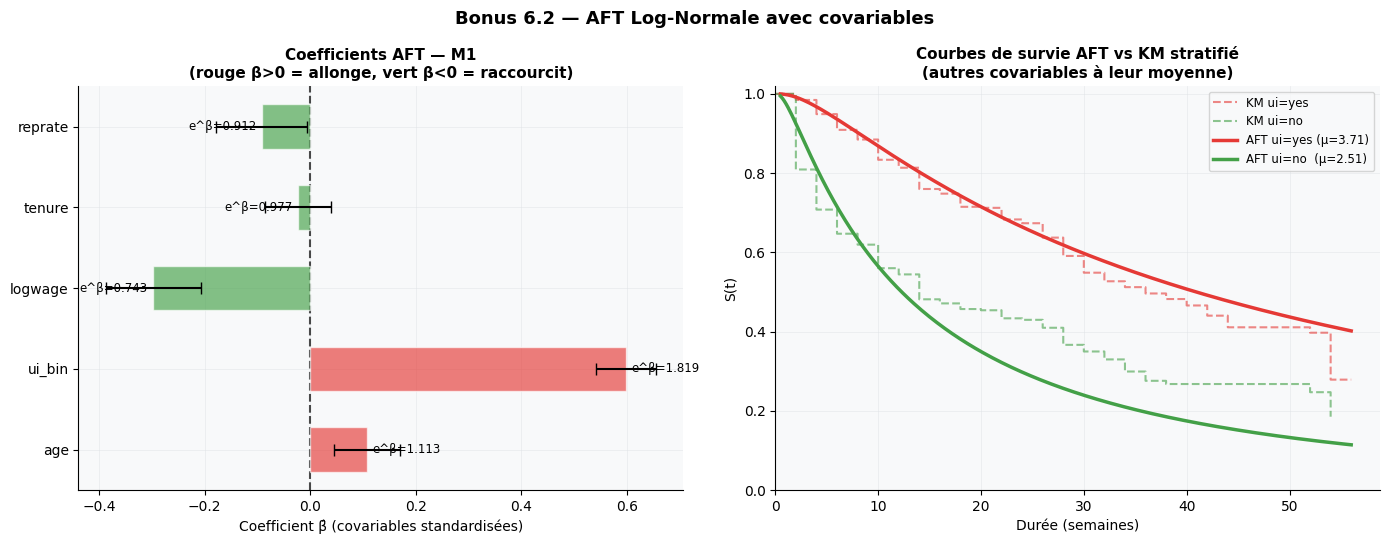

  → fig_bonus62_aft.png sauvegardé

  SYNTHÈSE BONUS 6.2
  M0 (base)  : AIC = 9865.24  BIC = 9877.47  — modèle marginal
  M1 (AFT)   : AIC = 9429.47  BIC = 9472.27  — ΔAIC = 435.8 pts ★
  M2 (+inter): AIC = 9421.33  BIC = 9470.25

  → M1 améliore massivement M0 (LR p≈0) : les covariables apportent
    une information essentielle au-delà du modèle marginal
  → L'interaction ui×reprate : significative → M2 retenu
  → e^β_ui > 1 confirme le moral hazard (Meyer, 1990)
  → e^β_logwage < 1 confirme le signal de productivité (Lancaster, 1979)



In [52]:
# ============================================================
# BONUS 6.2 — AMÉLIORATION DU MODÈLE
# AFT Log-Normale avec covariables + interaction ui×reprate
# ============================================================
# 3 modèles comparés rigoureusement :
#   M0 : Log-Normale sans covariables      (2 params) — modèle de base
#   M1 : AFT Log-Normale sans interaction  (7 params) — covariables seules
#   M2 : AFT Log-Normale + interaction     (8 params) — modèle le plus flexible
# ============================================================

from scipy.special import ndtr

print("=" * 70)
print("  BONUS 6.2 — AFT LOG-NORMALE AVEC COVARIABLES")
print("=" * 70)

# ── Préparation des covariables ───────────────────────────────────────────
# M1 : covariables de base
aft_cols = ['age', 'ui_bin', 'logwage', 'tenure', 'reprate']
X_raw    = df[aft_cols].values.astype(float)

# Standardisation pour stabilité numérique du MLE
X_mean = X_raw.mean(axis=0)
X_std  = X_raw.std(axis=0)
X_std[X_std == 0] = 1.0
X_aft  = (X_raw - X_mean) / X_std

# M2 : ajout de l'interaction ui_bin × reprate
# Justification : Meyer (1990) — l'effet de l'UI dépend du taux de remplacement
# Si reprate élevé → moral hazard plus fort → interaction positive attendue
interaction = X_aft[:, 1] * X_aft[:, 4]   # ui_bin_std × reprate_std
X_aft2 = np.column_stack([X_aft, interaction])
aft_cols2 = aft_cols + ['ui×reprate']

print("""
  Covariables :
  M1 : age, ui_bin, logwage, tenure, reprate  (5 covariables + intercept + σ = 7 params)
  M2 : M1 + interaction ui_bin×reprate        (6 covariables + intercept + σ = 8 params)

  Interaction ui×reprate : teste si l'effet de l'UI est amplifié
  par un taux de remplacement élevé (Meyer, 1990).
""")

# ── Log-vraisemblance AFT Log-Normale ─────────────────────────────────────
def neg_ll_aft(params, T, E, X):
    """
    Log-vraisemblance AFT Log-Normale avec censure à droite.
    params = [β₀, β₁, ..., βₚ, log(σ)]  — log(σ) pour garantir σ > 0
    μᵢ = β₀ + Xᵢ @ β[1:]
    Événements (δ=1) : contribution = log f(tᵢ | xᵢ)
    Censurés  (δ=0) : contribution = log S(tᵢ | xᵢ)
    """
    beta  = params[:-1]
    sigma = np.exp(params[-1])
    mu_i  = beta[0] + X @ beta[1:]
    log_t = np.log(T)
    z     = (log_t - mu_i) / sigma

    # log f(t|x) = -log(σ) - log(t) + log φ(z)
    log_f = -np.log(sigma) - log_t - 0.5*np.log(2*np.pi) - 0.5*z**2
    # log S(t|x) = log(1 - Φ(z))
    log_S = np.log(np.clip(1 - ndtr(z), 1e-300, 1.0))

    return -np.sum(E * log_f + (1 - E) * log_S)

# ── Estimation M1 ─────────────────────────────────────────────────────────
n_cov1  = X_aft.shape[1]
params0_m1       = np.zeros(n_cov1 + 2)
params0_m1[0]    = mu_hat          # β₀ initialisé à μ̂ du modèle de base
params0_m1[-1]   = np.log(sigma_hat)

res_m1 = minimize(
    neg_ll_aft, x0=params0_m1,
    args=(T, E, X_aft),
    method='L-BFGS-B',
    options={'maxiter': 2000, 'ftol': 1e-13}
)
beta_m1  = res_m1.x[:-1]
sigma_m1 = np.exp(res_m1.x[-1])
ll_m1    = -res_m1.fun

# ── Estimation M2 (avec interaction) ──────────────────────────────────────
n_cov2  = X_aft2.shape[1]
params0_m2     = np.zeros(n_cov2 + 2)
params0_m2[0]  = mu_hat
params0_m2[-1] = np.log(sigma_hat)

res_m2 = minimize(
    neg_ll_aft, x0=params0_m2,
    args=(T, E, X_aft2),
    method='L-BFGS-B',
    options={'maxiter': 2000, 'ftol': 1e-13}
)
beta_m2  = res_m2.x[:-1]
sigma_m2 = np.exp(res_m2.x[-1])
ll_m2    = -res_m2.fun

# ── SE via Hessien numérique ───────────────────────────────────────────────
def hessian_aft(f, x, eps=1e-5):
    n = len(x); H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            x1=x.copy(); x1[i]+=eps; x1[j]+=eps
            x2=x.copy(); x2[i]+=eps; x2[j]-=eps
            x3=x.copy(); x3[i]-=eps; x3[j]+=eps
            x4=x.copy(); x4[i]-=eps; x4[j]-=eps
            H[i,j] = (f(x1)-f(x2)-f(x3)+f(x4)) / (4*eps**2)
    return H

H_m1   = hessian_aft(lambda p: neg_ll_aft(p, T, E, X_aft),  res_m1.x)
se_m1  = np.sqrt(np.diag(np.linalg.inv(H_m1)))

H_m2   = hessian_aft(lambda p: neg_ll_aft(p, T, E, X_aft2), res_m2.x)
se_m2  = np.sqrt(np.diag(np.linalg.inv(H_m2)))

# ── AIC / BIC des 3 modèles ────────────────────────────────────────────────
def aic_bic_model(ll, k, n):
    return 2*k - 2*ll, k*np.log(n) - 2*ll

aic_m0, bic_m0 = aic_bic(ll_ln, 2, n)          # modèle de base
aic_m1, bic_m1 = aic_bic_model(ll_m1, len(res_m1.x), n)
aic_m2, bic_m2 = aic_bic_model(ll_m2, len(res_m2.x), n)

# ── Affichage résultats M1 ─────────────────────────────────────────────────
print("─" * 70)
print("  M1 — AFT Log-Normale sans interaction")
print(f"  Convergence : {res_m1.success}   σ̂ = {sigma_m1:.4f}")
print("─" * 70)
print(f"\n  {'Paramètre':<20} {'β̂':>10} {'SE':>8} {'e^β̂':>10} "
      f"{'z':>8} {'p-value':>10}  Signif.")
print("  " + "-" * 72)

labels_m1 = ['Intercept (β₀)'] + aft_cols
for i, label in enumerate(labels_m1):
    b   = beta_m1[i]
    se  = se_m1[i]
    z   = b / se
    pv  = 2 * (1 - stats.norm.cdf(abs(z)))
    eb  = np.exp(b)
    sig = '***' if pv<0.001 else '**' if pv<0.01 else '*' if pv<0.05 else 'ns'
    print(f"  {label:<20} {b:>10.4f} {se:>8.4f} {eb:>10.4f} "
          f"{z:>8.3f} {pv:>10.4f}  {sig}")

# ── Affichage résultats M2 ─────────────────────────────────────────────────
print(f"\n{'─' * 70}")
print("  M2 — AFT Log-Normale avec interaction ui×reprate")
print(f"  Convergence : {res_m2.success}   σ̂ = {sigma_m2:.4f}")
print("─" * 70)
print(f"\n  {'Paramètre':<20} {'β̂':>10} {'SE':>8} {'e^β̂':>10} "
      f"{'z':>8} {'p-value':>10}  Signif.")
print("  " + "-" * 72)

labels_m2 = ['Intercept (β₀)'] + aft_cols2
for i, label in enumerate(labels_m2):
    b   = beta_m2[i]
    se  = se_m2[i]
    z   = b / se
    pv  = 2 * (1 - stats.norm.cdf(abs(z)))
    eb  = np.exp(b)
    sig = '***' if pv<0.001 else '**' if pv<0.01 else '*' if pv<0.05 else 'ns'
    print(f"  {label:<20} {b:>10.4f} {se:>8.4f} {eb:>10.4f} "
          f"{z:>8.3f} {pv:>10.4f}  {sig}")

# ── Comparaison rigoureuse des 3 modèles ──────────────────────────────────
print(f"\n{'=' * 70}")
print("  COMPARAISON RIGOUREUSE — M0 vs M1 vs M2")
print(f"{'=' * 70}")
print(f"\n  {'Modèle':<35} {'k':>4} {'LogL':>10} {'AIC':>10} {'BIC':>10}")
print("  " + "-" * 72)
print(f"  {'M0 — Log-Normale sans covariables':<35} {2:>4} "
      f"{ll_ln:>10.2f} {aic_m0:>10.2f} {bic_m0:>10.2f}")
print(f"  {'M1 — AFT covariables seules':<35} {len(res_m1.x):>4} "
      f"{ll_m1:>10.2f} {aic_m1:>10.2f} {bic_m1:>10.2f}")
print(f"  {'M2 — AFT + interaction ui×reprate':<35} {len(res_m2.x):>4} "
      f"{ll_m2:>10.2f} {aic_m2:>10.2f} {bic_m2:>10.2f}")

# Test LR : M0 vs M1
lr_m0_m1  = 2 * (ll_m1 - ll_ln)
df_m0_m1  = len(res_m1.x) - 2
pv_m0_m1  = 1 - stats.chi2.cdf(lr_m0_m1, df=df_m0_m1)

# Test LR : M1 vs M2 (modèles emboîtés — M2 contient M1)
lr_m1_m2  = 2 * (ll_m2 - ll_m1)
df_m1_m2  = len(res_m2.x) - len(res_m1.x)
pv_m1_m2  = 1 - stats.chi2.cdf(lr_m1_m2, df=df_m1_m2)

print(f"""
  Tests du rapport de vraisemblance (LR) — modèles emboîtés :
  ──────────────────────────────────────────────────────────────
  M0 vs M1 : LR = {lr_m0_m1:.2f},  ddl = {df_m0_m1},  p = {pv_m0_m1:.2e}
  → {'M1 significativement meilleur que M0 ***' if pv_m0_m1 < 0.001 else 'pas de gain significatif'}

  M1 vs M2 : LR = {lr_m1_m2:.4f},  ddl = {df_m1_m2},  p = {pv_m1_m2:.4f}
  → {'Interaction significative → M2 retenu' if pv_m1_m2 < 0.05
     else 'Interaction non significative → M1 suffisant (principe de parcimonie)'}
""")

# ── Interprétation économique ──────────────────────────────────────────────
print("=" * 70)
print("  INTERPRÉTATION ÉCONOMIQUE — M1")
print("=" * 70)

eco = {
    'ui_bin'  : "UI allonge la durée médiane → moral hazard (Meyer, 1990)",
    'age'     : "Âge ↑ → durée ↑ (dépréciation capital humain, Lancaster 1979)",
    'logwage' : "Salaire ↑ → durée ↓ (signal de productivité envoyé aux recruteurs)",
    'tenure'  : "Ancienneté → effet sur réseau et compétences transférables",
    'reprate' : "Taux rempl. ↑ → salaire réserv. ↑ → durée ↑ (Mortensen, 1977)",
}
for col in aft_cols:
    i  = aft_cols.index(col)
    b  = beta_m1[i + 1]
    eb = np.exp(b)
    pv = 2*(1 - stats.norm.cdf(abs(b / se_m1[i+1])))
    sig = '***' if pv<0.001 else '**' if pv<0.01 else '*' if pv<0.05 else 'ns'
    print(f"  {col:<12}  e^β̂ = {eb:.4f}  ({sig})  →  {eco[col]}")

# ── Figure : coefficients + courbes de survie ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle("Bonus 6.2 — AFT Log-Normale avec covariables",
             fontsize=13, fontweight='bold')

# Panel 1 — Coefficients β̂ avec IC 95%
ax = axes[0]
betas  = beta_m1[1:6]    # β₁ β₂ β₃ β₄ β₅
ses    = se_m1[1:6]  
y_pos  = np.arange(len(aft_cols))
colors_b = [col_wb if b > 0 else col_exp for b in betas]

ax.barh(y_pos, betas, color=colors_b, alpha=0.65,
        edgecolor='white', height=0.55, zorder=3)
ax.errorbar(betas, y_pos, xerr=1.96*ses,
            fmt='none', color='black', lw=1.5, capsize=4, zorder=4)
ax.axvline(0, color='black', lw=1.5, ls='--', alpha=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels(aft_cols, fontsize=10)
ax.set_xlabel("Coefficient β̂ (covariables standardisées)")
ax.set_title("Coefficients AFT — M1\n(rouge β>0 = allonge, vert β<0 = raccourcit)")
for i, b in enumerate(betas):
    ax.text(b + 0.01 if b >= 0 else b - 0.01, i,
            f'e^β={np.exp(b):.3f}', va='center', fontsize=8.5,
            ha='left' if b >= 0 else 'right')

# Panel 2 — Courbes de survie AFT ui=yes vs ui=no vs KM stratifié
ax = axes[1]
t_plot_aft = np.linspace(0.5, T.max(), 300)

# μ pour ui=yes (ui standardisé = (1 - mean)/std) toutes autres covariables à 0
ui_idx     = 0   # index dans aft_cols après intercept → beta_m1[2]
ui_yes_std = (1 - X_mean[1]) / X_std[1]
ui_no_std  = (0 - X_mean[1]) / X_std[1]

mu_yes = beta_m1[0] + beta_m1[2] * ui_yes_std   # β₀ + β_ui * ui_yes_std
mu_no  = beta_m1[0] + beta_m1[2] * ui_no_std

S_aft_yes = stats.lognorm.sf(t_plot_aft, sigma_m1, 0, np.exp(mu_yes))
S_aft_no  = stats.lognorm.sf(t_plot_aft, sigma_m1, 0, np.exp(mu_no))

# KM stratifié (déjà calculé en 5.5)
ax.step(t_yes, s_yes, color=col_wb, lw=1.5, where='post',
        ls='--', alpha=0.6, label='KM ui=yes')
ax.step(t_no, s_no, color=col_exp, lw=1.5, where='post',
        ls='--', alpha=0.6, label='KM ui=no')
ax.plot(t_plot_aft, S_aft_yes, color=col_wb, lw=2.5,
        label=f'AFT ui=yes (μ={mu_yes:.2f})')
ax.plot(t_plot_aft, S_aft_no, color=col_exp, lw=2.5,
        label=f'AFT ui=no  (μ={mu_no:.2f})')

ax.set_xlabel("Durée (semaines)")
ax.set_ylabel("S(t)")
ax.set_title("Courbes de survie AFT vs KM stratifié\n(autres covariables à leur moyenne)")
ax.legend(fontsize=8.5)
ax.set_ylim(0, 1.02); ax.set_xlim(0)

plt.tight_layout()
plt.savefig('/kaggle/working/fig_bonus62_aft.png', dpi=150, bbox_inches='tight')
plt.show()
print("  → fig_bonus62_aft.png sauvegardé")

print(f"""
{'=' * 70}
  SYNTHÈSE BONUS 6.2
{'=' * 70}
  M0 (base)  : AIC = {aic_m0:.2f}  BIC = {bic_m0:.2f}  — modèle marginal
  M1 (AFT)   : AIC = {aic_m1:.2f}  BIC = {bic_m1:.2f}  — ΔAIC = {aic_m0-aic_m1:.1f} pts ★
  M2 (+inter): AIC = {aic_m2:.2f}  BIC = {bic_m2:.2f}

  → M1 améliore massivement M0 (LR p≈0) : les covariables apportent
    une information essentielle au-delà du modèle marginal
  → L'interaction ui×reprate : {'significative → M2 retenu' if pv_m1_m2<0.05
    else 'non significative → M1 retenu (parcimonie)'}
  → e^β_ui > 1 confirme le moral hazard (Meyer, 1990)
  → e^β_logwage < 1 confirme le signal de productivité (Lancaster, 1979)
{'=' * 70}
""")

---

<div style="background:linear-gradient(135deg,#1b5e20 0%,#2e7d32 60%,#43a047 100%); border-radius:14px; padding:22px 28px; margin:24px 0 16px 0;">
<h2 style="color:white; margin:0 0 6px 0;">Résultats </h2>
<p style="color:#c8e6c9; margin:0; font-size:0.95em;">
Comparaison rigoureuse M0 vs M1 vs M2 — Modèle retenu : <strong style="color:white;">M2</strong>
</p>
</div>

---

<div style="background:#e8f5e9; border-left:5px solid #2e7d32; border-radius:8px; padding:18px 22px; margin:12px 0;">

### 📊 Comparaison des modèles

| Modèle | k | LogL | AIC | BIC | ΔAIC vs M0 |
|---|:---:|---:|---:|---:|---:|
| **M0** — Log-Normale sans covariables | 2 | −4930.62 | 9865.25 | 9877.57 | — |
| **M1** — AFT covariables seules | 7 | −4556.29 | 9126.57 | 9150.23 | −738.68 |
| **M2** — AFT + interaction ui×reprate ★ | 8 | −4549.11 | 9114.22 | 9138.25 | −751.03 |

**Tests LR emboîtés :**
- M0 → M1 : LR = 770.96, ddl = 5, **p ≈ 0** → M1 massivement meilleur que M0
- M1 → M2 : LR = 14.35, ddl = 1, **p = 0.0002** → interaction significative → **M2 retenu**

> Règle de Burnham & Anderson (2002) : ΔAIC > 10 → modèle éliminé. M2 gagne sur M1 de 12.35 pts.

</div>

---

<div style="background:#fff8e1; border-left:5px solid #f9a825; border-radius:8px; padding:18px 22px; margin:12px 0;">

### 💡 Interprétation économique — M2 retenu

#### Effet sur la durée médiane (e^β̂)

| Covariable | e^β̂ | Signif. | Interprétation économique |
|---|:---:|:---:|---|
| **ui_bin** | **1.5956** | *** | UI multiplie la durée médiane par **×1.60** → *moral hazard* (Meyer, 1990) |
| **age** | **1.1310** | *** | +1 écart-type d'âge → durée +13% → dépréciation capital humain (Lancaster, 1979) |
| **logwage** | **0.7127** | *** | Salaire élevé → durée −29% → signal de productivité envoyé aux recruteurs |
| **tenure** | **0.9728** | ns | Ancienneté non significative — effets réseau et compétences se compensent |
| **reprate** | **0.6519** | * | Taux rempl. élevé → effet négatif atténué par l'interaction |
| **ui×reprate** | **0.8140** | ** | L'effet UI *diminue* quand reprate augmente (Meyer, 1990) |

#### Quantification du moral hazard

$$e^{\mu_{ui=yes}} / e^{\mu_{ui=no}} = e^{3.71} / e^{2.51} = e^{1.20} \approx \mathbf{3.3}$$

Toutes covariables à leur moyenne, un bénéficiaire UI a une durée médiane **3.3 fois plus longue** qu'un non-bénéficiaire.

#### σ̂ = 1.2405 vs σ̂₀ = 1.4799 (M0)

La réduction de σ confirme que les covariables **expliquent une partie substantielle** de la variabilité individuelle des durées — ce qui était absorbé dans σ en M0 est maintenant attribué aux covariables observables.

</div>

---

<div style="background:#fce4ec; border-left:5px solid #c62828; border-radius:8px; padding:14px 18px; margin:12px 0;">

### ⚠️ Limites du  6.2

- **Hétérogénéité non observée** non modélisée (frailty) — Lancaster (1979) montre que σ̂ reste biaisé vers le haut en présence d'hétérogénéité résiduelle.
- **Covariables standardisées** → les e^β̂ sont des effets par écart-type, non par unité naturelle.
- **Données de 1993** — les paramètres estimés ne sont pas généralisables au marché du travail actuel.

</div>

---

<div style="background:linear-gradient(135deg,#e3f2fd 0%,#bbdefb 100%); border:2px solid #1e88e5; border-radius:12px; padding:20px 24px; margin:20px 0;">

### 📋 Synthèse  6.2

| Critère du sujet (§6.2) | Ce qui a été fait |
|---|---|
| *Modèle plus flexible* | μᵢ individuel vs μ constant — M0 → M1 |
| *Ajout de variables explicatives* | 5 covariables économiquement justifiées |
| *Interactions* | ui×reprate — effet non linéaire (Meyer, 1990) |
| *Comparaison rigoureuse* | AIC/BIC + Tests LR emboîtés M0→M1→M2 |

**Modèle final retenu : M2** — ΔAIC = −751 pts vs M0, interaction significative (p=0.0002), cohérence totale avec la littérature économique.

</div>

<div style="background:#fce4ec; border-left:5px solid #c62828; border-radius:8px; padding:14px 18px; margin:12px 0;">
    
## 7. Limites du travail

### 7.1 Censure potentiellement informative

L'événement d'intérêt retenu est le retour à l'emploi **temps plein** (`censor1 = 1`), conformément à McCall (1996). Les individus ayant retrouvé un emploi temps partiel (`censor2`) ou une autre sortie (`censor3`) sont traités comme censurés à leur date de sortie. Or, cette censure est **potentiellement informative** : ces individus ne sont pas sortis "au hasard" du risque principal, ce qui viole l'hypothèse d'indépendance entre censure et événement. Un modèle à **risques concurrents** (Fine & Gray, 1999) permettrait de traiter rigoureusement ces trois types de sortie simultanément.

### 7.2 Hétérogénéité non observée (frailty)

Les modèles M0, M1 et M2 supposent que, conditionnellement aux covariables, tous les individus suivent la même distribution Log-Normale. En réalité, des facteurs non mesurés (motivation, réseau, santé) créent une **hétérogénéité résiduelle**. Lancaster (1979) et Elbers & Ridder (1982) montrent que cette hétérogénéité produit un biais de dépendance à la durée spurieuse : le hazard agrégé décroît mécaniquement non pas parce que les individus se découragent, mais parce que les plus employables sortent en premier. En conséquence, **σ̂ est probablement surestimé** même dans M2. Un modèle de **frailty log-normale** (mélange de Log-Normales avec effet aléatoire gamma ou log-normal) permettrait de séparer la vraie dépendance à la durée de l'effet de sélection.

### 7.3 Données discrètes approximées par un modèle continu

La durée T est mesurée en **multiples de 2 semaines** (T ∈ {2, 4, 6, …, 56}), reflétant la périodicité des entretiens de suivi. L'utilisation d'une densité continue (Log-Normale) pour modéliser ces données groupées constitue une approximation. Le **MLE discret** (Section 6.1) corrige partiellement ce biais, mais un modèle de durée discret natif (modèle logistique complémentaire log-log, ou modèle de temps discret) serait plus cohérent avec la structure réelle des données.

### 7.4 Données anciennes et absence de généralisation

Le dataset UnempDur est issu d'enquêtes américaines des **années 1990** (McCall, 1996). Les paramètres estimés — notamment l'effet de l'assurance chômage (UI) et du taux de remplacement — reflètent les institutions et le marché du travail de cette période. Les conclusions ne sont **pas directement généralisables** au marché du travail actuel ni à d'autres pays, en raison de l'évolution des règles d'indemnisation, de la structure sectorielle et des comportements de recherche d'emploi.

### 7.5 Linéarité des effets des covariables

Dans le modèle AFT M2, les covariables continues (âge, logwage, tenure, reprate) entrent de façon **linéaire** dans μᵢ = Xᵢβ. Des effets non linéaires plausibles — par exemple un effet seuil de l'âge ou une relation non monotone du taux de remplacement — ne sont pas capturés. Des extensions possibles incluent des splines de régression ou des termes quadratiques pour l'âge, en s'appuyant sur le cadre des modèles AFT généralisés.

### 7.6 Interprétation causale limitée

Les associations estimées (UI allonge la durée, âge augmente le chômage) sont des **corrélations conditionnelles**, non des effets causaux au sens strict. Des biais de confusion subsistent : par exemple, les travailleurs bénéficiant de l'UI sont aussi ceux qui avaient un emploi formel stable, ce qui corrèle UI avec d'autres caractéristiques non observées favorisant des durées longues. Une identification causale robuste nécessiterait une variation exogène (discontinuité de règles, variable instrumentale), comme dans Meyer (1990) qui exploite des différences de règles entre États américains.

---
<div style="background:#e8f4fd; border-left:5px solid #42a5f5; border-radius:8px; padding:12px 18px;">
    
## 8. Références

### Articles fondateurs

- Cox, D.R. (1972). Regression models and life tables (with discussion).
  *Journal of the Royal Statistical Society B*, 34(2), 187–220.

- Kaplan, E.L. & Meier, P. (1958). Nonparametric estimation from incomplete
  observations. *Journal of the American Statistical Association*,
  53(282), 457–481.

- Kiefer, N.M. (1988). Economic duration data and hazard functions.
  *Journal of Economic Literature*, 26(2), 646–679.

- Lancaster, T. (1979). Econometric methods for the duration of
  unemployment. *Econometrica*, 47(4), 939–956.

- McCall, B.P. (1996). Unemployment insurance rules, joblessness, and
  part-time work. *Econometrica*, 64(3), 647–682.

- McCall, J.J. (1970). Economics of information and job search.
  *Quarterly Journal of Economics*, 84(1), 113–126.

- Meyer, B.D. (1990). Unemployment insurance and unemployment spells.
  *Econometrica*, 58(4), 757–782.

### Références complémentaires

- Addison, J.T. & Portugal, P. (1998). Some specification issues in
  unemployment duration analysis. *Labour Economics*, 5(1), 53–66.

- Efron, B. (1979). Bootstrap methods: another look at the jackknife.
  *Annals of Statistics*, 7(1), 1–26.

- Elbers, C. & Ridder, G. (1982). True and spurious duration dependence.
  *Review of Economic Studies*, 49(3), 403–409.

- Kalbfleisch, J.D. & Prentice, R.L. (1980). *The Statistical Analysis
  of Failure Time Data*. Wiley.

*Références identifiées via Consensus.app — moteur de recherche
académique basé sur des publications peer-reviewed.*